### PRELIMINARY DATA EXPLORATION
> Results may differ, as each stage in the pipeline is thoroughly tested, this notebook is not.

> Shows the thought process in making the pipeline.

> For the network analysis exploration, please see the `networks.ipynb` notebook.

In [1]:
# Basic imports
import pandas as pd
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from ga4_ecommerce_analytics_engine.sources.bigquery_source import BigQuerySource
start = '2020-11-01'
end = '2021-01-31'
raw = BigQuerySource().fetch_all(start,end)

In [3]:
raw_events = raw.events.to_pandas()
print("Shape:", raw_events.shape)
print("\nColumns:", raw_events.columns.tolist())
print("\nA sample of the raw event data:")
display(raw_events.head())

Shape: (4295584, 13)

Columns: ['user_pseudo_id', 'session_id', 'session_number', 'event_date', 'event_timestamp_micros', 'event_name', 'session_engaged', 'engagement_time_msec', 'source', 'medium', 'campaign', 'page_referrer', 'page_path']

A sample of the raw event data:


,user_pseudo_id,session_id,session_number,event_date,event_timestamp_micros,event_name,session_engaged,engagement_time_msec,source,medium,campaign,page_referrer,page_path
0,1055969.5872512303,1055969.5872512303-5298604884,2,2021-01-02,2021-01-02 20:14:35.007287+00:00,user_engagement,1,3248.0,NaN,NaN,NaN,https://shop.googlemerchandisestore.com/basket...,/basket.html
1,1055969.5872512303,1055969.5872512303-5298604884,2,2021-01-02,2021-01-02 20:17:19.077394+00:00,page_view,1,NaN,NaN,NaN,NaN,https://shop.googlemerchandisestore.com/review...,/ordercompleted.html
2,1055969.5872512303,1055969.5872512303-9503003312,1,2021-01-02,2021-01-02 02:10:46.310467+00:00,scroll,1,113.0,NaN,NaN,NaN,https://shop.googlemerchandisestore.com/regist...,/registersuccess.html
3,1127197.7845904071,1127197.7845904071-770822302,1,2021-01-02,2021-01-02 21:21:43.214528+00:00,session_start,NaN,NaN,NaN,NaN,NaN,NaN,/
4,1134613.7634894426,1134613.7634894426-1896457604,1,2021-01-02,2021-01-02 22:48:54.657083+00:00,page_view,1,10.0,NaN,NaN,NaN,NaN,/


#### Raw Event DataFrame Summary

- **Dataset size**: 4,295,584 rows x 15 columns

- **Columns**:
    - **Events**
        - `user_pseudo_id` → Uniqe client ID for each user.
        <br>
        <br>
        - `session_id`→ Unique session ID for **a user**. Not unique across the dataset. Need to combine with `user_pseudo_id`.
        <br>
        <br>
        - `event_timestamp_micros` → Timestamp the event fired at.
        <br>
        <br>
        - `event_name` → The type of event fired.
        <br>
        <br>
    - **Engagement**
        - `session_engaged` → Whether the user is engaged in the session (0 or 1; int).
        <br>
        <br>
        - `engagement_time_msec` → The duration the event is engaged (in miliseconds).
        <br>
        <br>
    - **UTM**
        - `source` → The source of the campaign (may be obfuscated in this dataset).
        <br>
        <br>
        - `medium` → The medium of the campaign.
        <br>
        <br>
        - `campaign` → The campaign.
        <br>
        <br>
    - **Pages**
        - `page_referrer` → The page before the fired event (may be obfuscated in this dataset).
        <br>
        <br>
        - `page_path` → The page location where the fired event.
        <br>
        <br>
    - **Ecommerce**
        - `purchase_revenue` → The revenue after a `purchase` event fires.
        <br>
        <br>
        - `transaction_id` → Unique transaction ID (may be obfuscated in this dataset).
        <br>
        <br>
        - `total_item_quantity` → The number of items interacted when an ecommerce-type event is fired.

---
- The dataset is very large and dense, containing event data over 92 days (2020/11/01 - 2021/01/31).

- Each row represents a single event, of which there are **~$4.3$ million events.**

- Unique client id: `user_pseudo_id`

- **The `session_id` is not unique across the dataset**. Simply create a new unique id by combining or grouping by both the `user_pseudo_id` and `session_id`.

- Engagement metrics: `session engaged`, `engagement_time_msec`

- Contains three UTM columns: `source`, `medium`, and `campaign`.

- Contains previous and current page information: `page_referrer` and `page_path`, respectively.

- Contains ecommerce data: `purchase_revenue`, `transaction_id`, and `total_item_quantity`.


### 1.1 Event Proportions

In [4]:
event_types = raw_events['event_name'].value_counts().reset_index()
event_types['percent'] = (event_types['count'] / event_types['count'].sum() * 100).round(2).astype(str) + "%"
print("Event types summary:")
display(event_types)

Event types summary:


,event_name,count,percent
0,page_view,1350428,31.44%
1,user_engagement,1058721,24.65%
2,scroll,493072,11.48%
3,view_item,386068,8.99%
4,session_start,354970,8.26%
5,first_visit,257462,5.99%
6,view_promotion,190104,4.43%
7,add_to_cart,58543,1.36%
8,begin_checkout,38757,0.9%
9,select_item,31007,0.72%


- **Ecommerce event-types are a very small proportion with the conversion (`purchase`) being only $0.13$% of all events.**

### Items

In [9]:
raw_items = raw.items.to_pandas()
print('\nItems:')
display(raw_items.head(10))


Items:


,user_pseudo_id,event_timestamp_micros,session_id,session_number,event_date,event_name,session_engaged,engagement_time_msec,source,medium,...,page_referrer,page_path,transaction_id,item_name,item_brand,item_variant,item_category,price,quantity,item_revenue
0,1862279.2644343817,2021-01-02 16:08:33.477679+00:00,1862279.2644343817-5383679041,1,2021-01-02,view_item,1,3931.0,shop.googlemerchandisestore.com,referral,...,NaN,/asearch.html,(not set),Google Black Cloud Zip Hoodie,Google Cloud,(not set),,NaN,NaN,NaN
1,1862279.2644343817,2021-01-02 16:08:25.486761+00:00,1862279.2644343817-5383679041,1,2021-01-02,view_item,1,1111.0,NaN,NaN,...,NaN,/asearch.html,(not set),Google Black Cloud Zip Hoodie,Google Cloud,(not set),,NaN,NaN,NaN
2,7796608.5828633110,2021-01-02 02:06:26.919131+00:00,7796608.5828633110-8626225507,1,2021-01-02,begin_checkout,1,941.0,shop.googlemerchandisestore.com,referral,...,https://shop.googlemerchandisestore.com/basket...,/yourinfo.html,(not set),Google Land & Sea French Terry Sweatshirt,Google,SM,Shop by Brand,NaN,1.0,NaN
3,5476414.5180022673,2021-01-02 22:33:15.256109+00:00,5476414.5180022673-8978435139,1,2021-01-02,begin_checkout,1,2816.0,<Other>,<Other>,...,https://shop.googlemerchandisestore.com/yourin...,/yourinfo.html,(not set),Super G Unisex Joggers,Google,XS,Apparel,NaN,1.0,NaN
4,8196079.8521874659,2021-01-02 08:44:08.866523+00:00,8196079.8521874659-5681678232,1,2021-01-02,begin_checkout,1,161.0,(direct),(none),...,https://shop.googlemerchandisestore.com/basket...,/yourinfo.html,(not set),Google Bot (Multicolored),Google,Single Option Only,Lifestyle,NaN,1.0,NaN
5,40569893.9835575904,2021-01-02 12:56:09.231149+00:00,40569893.9835575904-5568359449,2,2021-01-02,begin_checkout,1,7.0,shop.googlemerchandisestore.com,referral,...,https://shop.googlemerchandisestore.com/signin...,/yourinfo.html,(not set),Google Yellow YoYo,Google,Single Option Only,New,NaN,1.0,NaN
6,5051426.0860421125,2021-01-02 22:39:32.520712+00:00,5051426.0860421125-9170501967,2,2021-01-02,begin_checkout,1,42.0,(direct),(none),...,https://shop.googlemerchandisestore.com/basket...,/yourinfo.html,(not set),Google Sunglasses,Google,RED,Uncategorized Items,NaN,1.0,NaN
7,25040095.0670087088,2021-01-02 14:32:40.418814+00:00,25040095.0670087088-8806289142,1,2021-01-02,begin_checkout,1,9.0,shop.googlemerchandisestore.com,referral,...,https://shop.googlemerchandisestore.com/yourin...,/yourinfo.html,(not set),Google Clear Framed Yellow Shades,Google,Single Option Only,Accessories,NaN,2.0,NaN
8,80435974.9462183494,2021-01-02 21:11:00.836510+00:00,80435974.9462183494-263104117,3,2021-01-02,begin_checkout,1,109.0,shop.googlemerchandisestore.com,referral,...,https://shop.googlemerchandisestore.com/signin...,/yourinfo.html,(not set),Google Women's Softshell Moss,Google,XL,Apparel,NaN,1.0,NaN
9,80435974.9462183494,2021-01-02 21:11:00.836510+00:00,80435974.9462183494-263104117,3,2021-01-02,begin_checkout,1,109.0,shop.googlemerchandisestore.com,referral,...,https://shop.googlemerchandisestore.com/signin...,/yourinfo.html,(not set),Google Women's Grid Zip-Up,Google,XL,Apparel,NaN,1.0,NaN


### 1.2 Cleaning the Event Data

#### Missing Values

In [10]:
# Count the number of nulls for each column
null_events = raw_events.isnull().sum().reset_index().rename(columns={'index':'event_columns', 0: 'nulls'})
null_events = null_events[null_events['nulls'].gt(0)].reset_index(drop=True)
null_events['percent'] = (null_events['nulls'] / raw_events.shape[0] * 100).round(2).astype(str) + '%'
total_nulls = null_events['nulls'].sum().astype(int)

print(f'Total number of nulls: {total_nulls}')
print(f'Percent nulls in entire dataframe: {round(total_nulls / (raw_events.shape[0] * raw_events.shape[1]) * 100, 2)}%')
print('\nMissing values:')
display(null_events.sort_values('percent', ascending=False))

Total number of nulls: 14224526
Percent nulls in entire dataframe: 25.47%

Missing values:


,event_columns,nulls,percent
5,page_referrer,3167806,73.75%
2,source,2867504,66.75%
3,medium,2856370,66.5%
4,campaign,2856417,66.5%
1,engagement_time_msec,1863766,43.39%
0,session_engaged,612663,14.26%


#### Missing Values Summary
- Sparse, there are a lot of `NULL` values, accounting for about $32$% of the dataframe.
<br>
<br>
- **Ecommerce**: `purchase_revenue` and `total_item_quantity` make up the largest proportion of missing values. This is a direct result of the low proportion of ecommerce events.
<br>
<br>
- **Obfuscation**: The `transaction_id`, `page_referrer`, and `source/medium/campaign` have many missing values since this is an obfuscated dataset. These should be handled appropriately.

#### Transaction Duplication

In [11]:
# A quick display of the items dataframe.
transaction_events = raw_items[raw_items['event_name'].eq('purchase')].sort_values(['user_pseudo_id', 'event_timestamp_micros']).reset_index()
# Fix NULL transaction_ids that have transaction information:
transaction_events['transaction_id'] = transaction_events.groupby(['user_pseudo_id', 'session_id', 'event_timestamp_micros'])['index'].transform('first')
transaction_events = transaction_events.groupby('transaction_id').agg(
    user_pseudo_id = ('user_pseudo_id', 'first'),
    session_id = ('session_id', 'first'),
    event_timestamp_micros = ('event_timestamp_micros', 'first'),
    purchase_revenue = ('item_revenue', 'sum'),
    basket_size = ('quantity', 'sum'),
    unique_items = ('quantity', 'count')
)

transaction_events

,user_pseudo_id,session_id,event_timestamp_micros,purchase_revenue,basket_size,unique_items
transaction_id,,,,,,
24,84647660.6681637188,84647660.6681637188-8224020962,2021-01-02 19:52:02.153896+00:00,183.0,11.0,7
1095,2876583.5568477554,2876583.5568477554-5734522237,2020-12-25 09:32:46.442281+00:00,19.0,1.0,1
1123,40059472.6231450399,40059472.6231450399-7396706089,2020-12-25 14:08:33.725567+00:00,30.0,9.0,5
1428,80435974.9462183494,80435974.9462183494-263104117,2021-01-02 21:12:37.166570+00:00,161.0,4.0,3
1446,85305313.7561330759,85305313.7561330759-6236563383,2021-01-02 20:25:56.551368+00:00,340.0,32.0,10
...,...,...,...,...,...,...
3938247,2241964.8178177438,2241964.8178177438-1825055532,2020-11-30 02:11:08.393660+00:00,118.0,31.0,13
3938253,2049470.1567030647,2049470.1567030647-4622494158,2020-11-30 20:25:59.629987+00:00,470.0,25.0,16
3938259,7680193331.8740202405,7680193331.8740202405-3806868337,2020-11-30 18:16:06.940366+00:00,443.0,31.0,18


- At the item-level scope, the ecommerce data is more abundant. It would be safer to use these events and join the dataframe to the raw_events dataframe.
<br>
<br>
- We first aggregate to a single transaction per row, where we just need the first event_timestamp, the sum of item_revenue, sum of quantity, and count to get the number of unique items.

In [12]:
from ga4_ecommerce_analytics_engine.cleaning.transactions import DataCleaner
clean = DataCleaner().clean_transactions(raw.events, raw.items)

clean_events = clean.events.to_pandas()
print(f"Cleaned data size: {clean_events.shape[0]}")
print(f"Data reduced by: {round((1 - (clean_events.shape[0] / raw_events.shape[0]) ) * 100,2)}%")

print('Deduplicated transaction events for purchase events:')
display(clean_events[clean_events['event_name'].eq('purchase')].head())

Cleaned data size: 4295134
Data reduced by: 0.01%
Deduplicated transaction events for purchase events:


,user_pseudo_id,session_id,session_number,event_date,event_timestamp_micros,event_name,session_engaged,engagement_time_msec,source,medium,campaign,page_referrer,page_path,transaction_id,event_value,basket_size,unique_items,conversion_timestamp
3437,10092926.3786306416,10092926.3786306416-8014902521,1,2021-01-22,2021-01-22 05:37:36.871176+00:00,purchase,1,5.0,shop.googlemerchandisestore.com,referral,(referral),https://shop.googlemerchandisestore.com/review...,/ordercompleted.html,10092926.3786306416-8014902521-1611293856871176,89.0,2.0,2.0,2021-01-22 05:37:36.871176+00:00
5008,10111055.8768683862,10111055.8768683862-6975932005,1,2020-12-10,2020-12-10 12:28:54.901943+00:00,purchase,1,2.0,NaN,NaN,NaN,NaN,/ordercompleted.html,10111055.8768683862-6975932005-1607603334901943,94.0,3.0,3.0,2020-12-10 12:28:54.901943+00:00
7078,1014825.0200289249,1014825.0200289249-2716419230,1,2020-11-03,2020-11-03 07:56:06.881926+00:00,purchase,1,NaN,NaN,NaN,NaN,NaN,/ordercompleted.html,1014825.0200289249-2716419230-1604390166881926,184.0,6.0,5.0,2020-11-03 07:56:06.881926+00:00
7759,1016446.8237887674,1016446.8237887674-2633554037,2,2020-12-21,2020-12-21 11:33:37.964725+00:00,purchase,1,8.0,google,organic,(organic),https://shop.googlemerchandisestore.com/review...,/ordercompleted.html,1016446.8237887674-2633554037-1608550417964725,85.0,6.0,6.0,2020-12-21 11:33:37.964725+00:00
8381,10172849.5375293351,10172849.5375293351-4974585843,1,2020-12-09,2020-12-09 07:31:52.105600+00:00,purchase,1,1.0,NaN,NaN,NaN,NaN,/ordercompleted.html,10172849.5375293351-4974585843-1607499112105600,155.0,6.0,6.0,2020-12-09 07:31:52.105600+00:00


### 1.3 Creating Campaign Channels

#### Extracting Earliest UTM
- Each row in the raw events dataset contains an event, which may or may not contain an empty `source/medium/campaign` UTM.
<br>
<br>
- We need to grab the **earliest, non-empty** UTM for each session to create a channel from this dataset.

In [13]:
events = clean_events.copy()

# Deprioritize initalization events: `session_start` and `first_visit`. They are problematic for datasets before Nov. 2nd, 2023.
events['event_is_initialization'] = np.where(~events['event_name'].isin(['session_start','first_visit']), 0, 1)

# Priorize all non-empty source values.
events['source_is_na'] = np.where(events['source'].isna(), 1, 0)

# Get the UTM source/medium/campaign
sessions_UTM = events.sort_values(['user_pseudo_id', 'session_id', 'event_is_initialization', 'source_is_na', 'event_timestamp_micros']).groupby(['user_pseudo_id', 'session_id']).agg(
    source_utm = ('source', 'first'),
    medium_utm = ('medium', 'first'),
    campaign_utm = ('campaign', 'first')
).reset_index()

# Make a quick check
events_UTM = (events.merge(sessions_UTM, on=['user_pseudo_id', 'session_id'], how='left')
              .sort_values(['user_pseudo_id','session_id','event_timestamp_micros'])
)

print(f"Number of rows: {events_UTM.shape[0]} rows; this matches the deduplicated events.")
print('\nEvents with UTM:')
display(events_UTM[['user_pseudo_id', 'session_id', 'event_timestamp_micros', 'event_name', 
                'source', 'medium', 'campaign', 'source_utm', 'medium_utm', 'campaign_utm']].head(10))

df_cols = events.columns.to_list()
utm_cols = ['source_utm', 'medium_utm', 'campaign_utm']
transformed_events = events_UTM[df_cols + utm_cols]

Number of rows: 4295134 rows; this matches the deduplicated events.

Events with UTM:


,user_pseudo_id,session_id,event_timestamp_micros,event_name,source,medium,campaign,source_utm,medium_utm,campaign_utm
0,10001363.4360935308,10001363.4360935308-5983736405,2020-12-12 04:11:17.508078+00:00,first_visit,NaN,NaN,NaN,google,organic,(organic)
1,10001363.4360935308,10001363.4360935308-5983736405,2020-12-12 04:11:17.508078+00:00,session_start,NaN,NaN,NaN,google,organic,(organic)
2,10001363.4360935308,10001363.4360935308-5983736405,2020-12-12 04:11:17.508078+00:00,page_view,google,organic,(organic),google,organic,(organic)
3,10001363.4360935308,10001363.4360935308-5983736405,2020-12-12 04:11:32.809866+00:00,user_engagement,google,organic,(organic),google,organic,(organic)
4,1000223163.8035209215,1000223163.8035209215-6063162078,2021-01-07 18:35:34.089387+00:00,first_visit,NaN,NaN,NaN,(direct),(none),(direct)
5,1000223163.8035209215,1000223163.8035209215-6063162078,2021-01-07 18:35:34.089387+00:00,session_start,NaN,NaN,NaN,(direct),(none),(direct)
6,1000223163.8035209215,1000223163.8035209215-6063162078,2021-01-07 18:35:34.089387+00:00,page_view,(direct),(none),(direct),(direct),(none),(direct)
7,1000223163.8035209215,1000223163.8035209215-6063162078,2021-01-07 18:35:39.094280+00:00,scroll,NaN,NaN,NaN,(direct),(none),(direct)
8,1000223163.8035209215,1000223163.8035209215-6063162078,2021-01-07 18:35:39.094280+00:00,page_view,NaN,NaN,NaN,(direct),(none),(direct)
9,1000223163.8035209215,1000223163.8035209215-6063162078,2021-01-07 18:35:44.561794+00:00,user_engagement,(direct),(none),(direct),(direct),(none),(direct)


- **Event UTMS are correct for this sample table visualization**

In [14]:
source_counts = sessions_UTM['source_utm'].value_counts()
medium_counts = sessions_UTM['medium_utm'].value_counts()
campaign_counts = sessions_UTM['campaign_utm'].value_counts()

print(f"Number of unique UTM sources  : {len(source_counts)}")
print(f"Number of unique UTM mediums  : {len(medium_counts)}")
print(f"Number of unique UTM campaigns: {len(campaign_counts)}")
print('---')
print('Unique UTM mediums:')
display(medium_counts)
print('Unique UTM campaigns:')
display(campaign_counts)

Number of unique UTM sources  : 235
Number of unique UTM mediums  : 8
Number of unique UTM campaigns: 12
---
Unique UTM mediums:


medium_utm
organic           101750
referral           84917
(none)             37839
<Other>            25364
cpc                 7684
(data deleted)      6493
affiliate           1330
email                197
Name: count, dtype: int64

Unique UTM campaigns:


campaign_utm
(organic)           101750
(referral)           84919
(direct)             37839
<Other>              33174
(data deleted)        6362
Data Share Promo      1321
NewYear_V1              67
NewYear_V2              39
Holiday_V2              38
BlackFriday_V2          24
Holiday_V1              17
BlackFriday_V1           8
Name: count, dtype: int64

#### UTM summary
- **Campaigns (n = 12)**:
    - **Non-specific Campaigns**: `(organic)`, `(referral)`, `(direct)`, `<Other>`
    <br>
    <br>
    - **Non-enabled Cookies**: `(data deleted)`
    <br>
    <br>
    - **Specific Campaign - Newsletters**: Contains `NewYear`, `Holiday`, and `BlackFriday`
    <br>
    <br>
    - **Specific Campaign**: `Data Share Promo`
    <br>
    <br>
- **Mediums (n = 8)**:
    - **Non-specific Mediums**: `organic`, `referral`, `<Other>` 
    <br>
    <br>
    - **Non-enabled Cookies**: `(data deleted)`
    <br>
    <br>
    - **Obfuscation**: `(none)`
    <br>
    <br>
    - **Paid Search**: `(cpc)`
    <br>
    <br>
    - **Affiliation**: `affiliate`
    <br>
    <br>
    - **Email**: `email`
    <br>
    <br>
- **Sources (n = 235)**:
    - Contains the more specific data to partition channels with.
---

#### Defining the Channel Using Source/Medium/Campaign Values

1. **Direct**: source contains `googlemerchandisestore.com` or source is `(direct)`
<br>
<br>
2. **Obfuscated**: Source/medium is `(data deleted)`
<br>
<br>
4. **Paid Search**: Medium is `cpc`
<br>
<br>
5. **Organic Search**: Medium is `organic` OR source contains `google`, `bing`, `baidu`, `yahoo`, `ecosia`
<br>
<br>
6. **Newsletter**: Source contains `newsletter`
<br>
<br>
7. **Affilitate**: Medium is `affiliate`
<br>
<br>
8. **Organic Social**: Source contains a social media domain
<br>
<br>
9. **Organic Video**: Source is a well known video platform domain
<br>
<br>
10. **Display**: Source contains `safeframe.googlesyndication.com`, `doubleclick.net`, or `2mdn.net`
<br>
<br>
11. **Internal**: Source is an internal Google tool (`corp.google.com`, `docs.google.com`, `sites.google.com`, `keep.google.com`, `groups.google.com`, `analytics.google.com`, `support.google.com`)
<br>
<br>
12. **Qwiklabs**: Source contains `qwiklabs.com`
<br>
<br>
13. **Unclassified**: Source/medium is '<Other>'
<br>
<br>
14. **Referral**: Everything else whose medium is `referral`

In [15]:
def channels(current_df: pd.DataFrame, gmail: bool = False) -> None:
    '''
    Creates a new channel column by combining the UTM parameter information for an appropriate channel value.

    parameters:
    -----------
        gmail: A boolean. If True a channel called 'G-Mail' is created.
            ('mail.google.com' has patterns very similiar to the catch-all '(direct)' source
                and the page_referrer field only has NaNs. 
                With caution, gmail set to True is more
                then likely incorrect. It is only here for data exploration purposes and to show
                its error.) 

    returns:
    --------
        None. Sets a attribute to an aggregated transaction-level dataframe that contains a channel column.
    '''

    print('Creating channels')
    ch = current_df.copy()

    # Normalizing
    ch.loc[ch['source_utm'].str.contains('googlesyndication'), 'source_utm'] = 'googlesyndication'
    ch.loc[ch['source_utm'].str.contains('bing'), 'source_utm'] = 'bing'
    ch.loc[ch['source_utm'].str.contains('yahoo'), 'source_utm'] = 'yahoo'
    ch.loc[ch['source_utm'].str.contains('facebook'), 'source_utm'] = 'facebook'
    ch.loc[ch['source_utm'].str.contains('reddit'), 'source_utm'] = 'reddit'
    ch.loc[ch['source_utm'].str.contains('googlemerchandisestore.com'), 'source_utm'] = 'googlemerchandisestore'
    ch.loc[ch['source_utm'].str.contains('doubleclick.net'), 'source_utm'] = 'doubleclick'
    ch.loc[ch['source_utm'].str.contains('qwiklabs'), 'source_utm'] = 'qwiklabs'

    source = ch["source_utm"].fillna("").astype(str).str.lower().str.strip()
    medium = ch["medium_utm"].fillna("").astype(str).str.lower().str.strip()
    campaign = ch["campaign_utm"].fillna("").astype(str).str.lower().str.strip()

    # Defining the conditions ordered by priority
    conditions = [
        # Priority 1: Direct
        source.eq('(direct)') & medium.eq('(none)') | source.eq('googlemerchandisestore'),
        # Priority 2: Paid Search
        medium.eq('cpc'),
        # Priority 3: Email (catch-all for email traffic)
        source.eq('mail.google.com'),
        # Priority 4: Newsletter
        source.str.contains('newsletter'),
        # Priority 5: Organic Search
        medium.eq('organic') | source.isin(['google', 'baidu', 'ecosia.org', 'yahoo', 'bing']),
        # Priority 6: Organic Social
        source.isin([
            'reddit', 'facebook', 'l.instagram.com', 'l.messenger', 
            'linkedin.com', 'pinterest.com', 't.co'
            ]),
        # Priority 7: Organic Video
        source.str.contains('youtube'),
        # Prority 8: Data Share Promo
        campaign.eq('data share promo'),
        # Priority 9: Affiliate
        medium.eq('affiliate'),
        # Priority 10: Display ads
        source.eq('googlesyndication')
        | source.eq('doubleclick')
        | source.str.contains('2mdn.net'),
        # Priority 11: Internal
        source.isin([
            'corp.google.com', 'docs.google.com', 'sites.google.com',
            'keep.google.com', 'groups.google.com',
            'analytics.google.com', 'support.google.com', 'moma.corp.google.com'
        ]),
        # Priority 12: Qwiklabs
        source.str.contains('qwiklabs'),
        # Priority 13: Redacted
        source.str.contains('data deleted')
        | medium.str.contains('data deleted')
        | campaign.str.contains('data deleted'),
        # Priority 14: Referral
        source.str.contains(r"\.com|\.net|\.org")
        | medium.eq('referral')
    ]

    channel_labels = [
        'Direct', 'Paid Search', 'Email', 'Newsletter',
        'Organic Search', 'Organic Social', 'Organic Video',
        'Data Share Promo', 'Affiliate', 'Display Ads',
        'Internal', 'Qwiklabs', 'Redacted', 'Referral'
    ]

    ch['channel'] = np.select(
        conditions, channel_labels, default='Unclassified'
    )
    return ch

session_channels = channels(sessions_UTM, gmail=True)

print('\nSessions with a channel column:')
display(session_channels.head())

print('\n Number and percent of channels')
channel_summary = session_channels['channel'].value_counts().reset_index()
channel_summary['percent of sessions'] = (channel_summary['count'] / channel_summary['count'].sum() * 100).round(2).astype(int).astype(str) + '%'
display(channel_summary)

Creating channels

Sessions with a channel column:


,user_pseudo_id,session_id,source_utm,medium_utm,campaign_utm,channel
0,10001363.4360935308,10001363.4360935308-5983736405,google,organic,(organic),Organic Search
1,1000223163.8035209215,1000223163.8035209215-6063162078,(direct),(none),(direct),Direct
2,1000299.7413851356,1000299.7413851356-3338398581,(direct),(none),(direct),Direct
3,1000300.3223254235,1000300.3223254235-3614622791,googlemerchandisestore,referral,(referral),Direct
4,1000300.3223254235,1000300.3223254235-9350310735,<Other>,<Other>,<Other>,Unclassified



 Number and percent of channels


,channel,count,percent of sessions
0,Unclassified,119918,33%
1,Organic Search,101787,28%
2,Direct,95434,26%
3,Referral,21196,5%
4,Paid Search,7684,2%
5,Redacted,6494,1%
6,Internal,4342,1%
7,Data Share Promo,1321,0%
8,Organic Video,923,0%
9,Display Ads,290,0%


**Notes:** Channels look correct for this sample visualization table. Should check further. 


### Aggregating to Session-level Data

#### Conversions at the session-level

In [16]:
transactions = transformed_events[transformed_events['event_name'].eq('purchase')]

session_conversions = transactions.sort_values(['user_pseudo_id', 'session_id', 'conversion_timestamp']).groupby(['user_pseudo_id', 'session_id']).agg(
    conversion_timestamp = ('conversion_timestamp', 'first'),
    revenue = ('event_value', 'sum'),
    quantity = ('basket_size', 'sum'),
    conversions_in_session = ('conversion_timestamp', 'count')
).reset_index()

print(f"Number of rows: {session_conversions.shape[0]}")
print(f"Rows reduced by: {round(100 - session_conversions.shape[0] / transactions.shape[0] * 100, 2)}%")

print('Sample of sessions that converted:')
display(session_conversions.head())

Number of rows: 4446
Rows reduced by: 15.19%
Sample of sessions that converted:


,user_pseudo_id,session_id,conversion_timestamp,revenue,quantity,conversions_in_session
0,10092926.3786306416,10092926.3786306416-8014902521,2021-01-22 05:37:36.871176+00:00,89.0,2.0,1
1,10111055.8768683862,10111055.8768683862-6975932005,2020-12-10 12:28:54.901943+00:00,94.0,3.0,1
2,1014825.0200289249,1014825.0200289249-2716419230,2020-11-03 07:56:06.881926+00:00,184.0,6.0,1
3,1016446.8237887674,1016446.8237887674-2633554037,2020-12-21 11:33:37.964725+00:00,85.0,6.0,1
4,10172849.5375293351,10172849.5375293351-4974585843,2020-12-09 07:31:52.105600+00:00,155.0,6.0,1


In [17]:
import polars as pl

df_pl = pl.from_pandas(transformed_events)
sessions = df_pl.sort(['user_pseudo_id','session_id','event_timestamp_micros']).group_by(['user_pseudo_id','session_id']).agg([
    pl.col('event_name').is_in(['page_view']).sum().alias('page_views'),
    pl.col('event_name').is_in(['view_item']).sum().alias('items_viewed'),
    pl.col('event_name').is_in(['add_to_cart']).sum().alias('carted'),
    pl.col('event_name').is_in(['begin_checkout']).sum().alias('checked_out'),
    pl.col('event_timestamp_micros').first().alias('session_start'),
    pl.col('event_date').first().alias('session_date'),
    pl.col('session_number').max().alias('session_number'),
    pl.col('engagement_time_msec').sum().alias('engagement_time'),
    pl.col('session_engaged').max().alias('session_engaged')
])

sessions = sessions.to_pandas()

sessions = (sessions
            .merge(session_channels, on = ['user_pseudo_id', 'session_id'], how='left')
            .merge(session_conversions, on = ['user_pseudo_id', 'session_id'], how='left')
)

sessions = sessions.rename(columns={'session_id': 'ga_session_id'})
sessions['session_id'] = sessions['user_pseudo_id']+ '-' + sessions['ga_session_id'].astype(str) 
sessions['session_engaged'] = sessions['session_engaged'].fillna(2).astype(int)
sessions['session_engaged'] = sessions['session_engaged'].replace(2,pd.NA)
sessions['converted'] = np.where(sessions['conversions_in_session'].gt(0), 1, 0)
sessions['source_utm'] = sessions['source_utm'].fillna('').astype(str)
sessions['medium_utm'] = sessions['medium_utm'].fillna('').astype(str)
sessions['campaign_utm'] = sessions['campaign_utm'].fillna('').astype(str)


print("==========Session Summary==========")
print(f"Number of sessions in the dataset: {sessions.shape[0]}")
print(f"Average number of session per day: {int(sessions.shape[0] / 92)}")
print(f"Number of users in the dataset   : {sessions['user_pseudo_id'].nunique()}")
print(f"Number of conversions            : {sessions['conversions_in_session'].sum().astype(int)}")
print(f"Percent of sessions that convert : {round(sessions['conversions_in_session'].sum() / sessions.shape[0] * 100, 2)}%")
print(f"Number of unique converters      : {sessions[sessions['converted'].eq(1)]['user_pseudo_id'].nunique()}")
print(f"Average conversions per day      : {int(sessions['conversions_in_session'].sum() / 92)}")
print('\n')

print("=========Engagement Summary========")
print(f"Average time engaged per session : {round(sessions['engagement_time'].mean() / 1000 / 60, 2)} minutes")
print(f"Number of sessions engaged       : {sessions['session_engaged'].sum()}")
print(f"Percent of sessions engaged      : {round(sessions['session_engaged'].sum() / sessions.shape[0] * 100, 2)}%")
print('\n')

print("=========Ecommerce Summary=========")
print(f"Total revenue                    : ${sessions['revenue'].sum().astype(int)}")
print(f"Average revenue per session      : ${sessions['revenue'].mean().astype(int)}")
print(f"Total items bought               : {sessions['quantity'].sum().astype(int)}")
print(f"Average items bought per sesison : {int(np.ceil(sessions['quantity'].mean()))}")
print('\n')

print("=========Channel Summary===========")
channel_summary = sessions.groupby('channel').agg(
    sessions = ('user_pseudo_id', 'count'),
    conversions = ('conversions_in_session', 'sum'),
    revenue = ('revenue', 'sum'),
    
)
channel_summary['percent of data'] = (channel_summary['sessions'] / channel_summary['sessions'].sum() * 100).round(2).astype(int).astype(str) + '%'
display(channel_summary.sort_values('sessions', ascending=False))

print("\n Sessions:")
display(sessions.head())

==========Session Summary==========
Number of sessions in the dataset: 360129
Average number of session per day: 3914
Number of users in the dataset   : 270154
Number of conversions            : 5242
Percent of sessions that convert : 1.46%
Number of unique converters      : 4066
Average conversions per day      : 56


=========Engagement Summary========
Average time engaged per session : 1.17 minutes
Number of sessions engaged       : 241932
Percent of sessions engaged      : 67.18%


=========Ecommerce Summary=========
Total revenue                    : $360085
Average revenue per session      : $80
Total items bought               : 22674
Average items bought per sesison : 6


=========Channel Summary===========


,sessions,conversions,revenue,percent of data
channel,,,,
Unclassified,119918,137.0,8981.0,33%
Organic Search,101787,1760.0,113008.0,28%
Direct,95434,1910.0,141182.0,26%
Referral,21196,1073.0,74803.0,5%
Paid Search,7684,48.0,3175.0,2%
Redacted,6494,223.0,13305.0,1%
Internal,4342,46.0,2727.0,1%
Data Share Promo,1321,2.0,166.0,0%
Organic Video,923,3.0,70.0,0%



 Sessions:


,user_pseudo_id,ga_session_id,page_views,items_viewed,carted,checked_out,session_start,session_date,session_number,engagement_time,...,source_utm,medium_utm,campaign_utm,channel,conversion_timestamp,revenue,quantity,conversions_in_session,session_id,converted
0,7009781.9704668951,7009781.9704668951-4038048404,2,0,0,0,2021-01-18 06:18:06.975780+00:00,2021-01-18,1,25.0,...,google,organic,(organic),Organic Search,NaT,NaN,NaN,NaN,7009781.9704668951-7009781.9704668951-4038048404,0
1,22049251.3437132849,22049251.3437132849-2685042615,2,0,0,0,2020-11-23 17:25:48.160536+00:00,2020-11-23,4,18754.0,...,google,organic,(organic),Organic Search,NaT,NaN,NaN,NaN,22049251.3437132849-22049251.3437132849-268504...,0
2,50008027.1032278893,50008027.1032278893-6395683108,1,0,0,0,2021-01-15 08:00:58.892396+00:00,2021-01-15,3,32.0,...,google,organic,(organic),Organic Search,NaT,NaN,NaN,NaN,50008027.1032278893-50008027.1032278893-639568...,0
3,32776048.0720983585,32776048.0720983585-8915533246,2,0,0,0,2020-11-22 19:18:41.663392+00:00,2020-11-22,1,146787.0,...,,,,Unclassified,NaT,NaN,NaN,NaN,32776048.0720983585-32776048.0720983585-891553...,0
4,8255994.4259406150,8255994.4259406150-3075277519,2,1,0,0,2021-01-21 10:25:33.683066+00:00,2021-01-21,1,2131.0,...,<Other>,<Other>,<Other>,Unclassified,NaT,NaN,NaN,NaN,8255994.4259406150-8255994.4259406150-3075277519,0


- **Insights:** This dataset has a lot of daily traffic and has a conversion rate of around $1.5$% with many aquisition channels bringing in a total of \$ $336,550$ across $21,222$ items. 

- How each channel contributes to a conversion has yet to be modeled and analyzed.

### Ecommerce Funnel

As we see with the table below, there is a clear funnel with respect to the event-types:

In [14]:
event_types = transformed_events['event_name'].value_counts().reset_index()
event_types['percent'] = (event_types['count'] / event_types['count'].sum() * 100).round(2).astype(str) + "%"
print("Event types summary:")
display(event_types)

Event types summary:


,event_name,count,percent
0,page_view,1350428,31.44%
1,user_engagement,1058721,24.65%
2,scroll,493072,11.48%
3,view_item,386068,8.99%
4,session_start,354970,8.26%
5,first_visit,257462,5.99%
6,view_promotion,190104,4.43%
7,add_to_cart,58543,1.36%
8,begin_checkout,38757,0.9%
9,select_item,31007,0.72%


Let us construct the following funnel:
- `session_start` → `view_item` → `add_to_cart` → `begin_checkout` → `add_shipping` → `add_payment` → `purchase`
<br>
<br>
    - There is an issue with the `session_start` event that was fixed in Nov. 2nd, 2023. This dataset is from 2020-2021. To avoid this issue, the funnel will start with the total number of users rather than the `session_start` event. (See: https://tanelytics.com/ga4-session_start-and-first_visit-events/).
<br>
<br>
- Number_of_users → `view_item` → `add_to_cart` → `begin_checkout` → `add_shipping` → `add_payment` → `purchase`

In [18]:
import plotly
event_funnel = transformed_events.groupby(['event_name'])['user_pseudo_id'].nunique().reset_index().reset_index(drop=True).rename(columns={'user_pseudo_id': 'unique_user_count'})
event_funnel.loc[len(event_funnel)] = ['total_users', raw_events['user_pseudo_id'].nunique()]
event_funnel = event_funnel[event_funnel['event_name'].isin([
    'total_users','view_item', 'add_to_cart', 'begin_checkout', 'add_shipping_info', 'add_payment_info', 'purchase'])
    ].sort_values('unique_user_count', ascending=False)

import plotly.graph_objects as go

stages = ['Visitors', 'Product', 'Cart', 'Checkout', 'Shipping', 'Payment', 'Purchase']

values = event_funnel['unique_user_count'].tolist()

fig = go.Figure(go.Funnel(
    y=stages,
    x=values,
    textinfo='value+percent initial',
    marker={"color": ["#1f83cf", "#1f83cf", "#1f83cf", 
                      "#1f83cf", "#1f83cf", "#1f83cf", "#21af32"]}
))


fig.update_layout(
    title="Ecommerce Conversion Analysis",
    font_size=12
)

fig


**User Funnel Summary**:
- ~$(77\%)$ drop going from entering the website to viewing a product **(loses the vast majority of users)**. 
<br>
<br>
- ~$(79.5\%)$ drop going from viewing the product to carting **(most do not find a need for the products)**. 
<br>
<br>
- ~$(23\%)$ drop going from carting to checkout **(going from this stage to the next looks normal)**. 
<br>
<br>
- ~$(0\%)$ drop going from checkout to shipping **(no friction at all; this stage is good.)**.
<br>
<br>
- ~$(41\%)$ going from shipping to payment **(lots of friction here)**.
<br>
<br>
- ~$(23\%)$ going from payment to purchase.
<br>
<br>
- **Insights**:
    - **Shipping costs may be too high**: There is friction between shipping and payment, which points to an issue with shipping most likely the shipping costs.
    <br>
    <br>
    - The vast majority of users who enter the store leave before viewing the product. This could be due to a mis-click or page design.
    
    

### Item Conversion & Pareto/ABC Analysis

#### Item Revenue and Median Price

In [19]:
# Get each item's total revenue and median price.
items = raw_items.copy()
items.loc[items['event_name'].eq('purchase') & items['transaction_id'].isna(), 'transaction_id'] = '(not set)'
item_revenue = items.groupby('item_name').agg(
    revenue = ('item_revenue', 'sum'),
    median_price = ('price', 'median') 
)
display(item_revenue.head())

,revenue,median_price
item_name,,
#IamRemarkable Journal,633.0,6.0
#IamRemarkable Ladies T-Shirt,331.0,10.0
#IamRemarkable Lapel Pin,90.0,2.0
#IamRemarkable Pen,127.0,17.0
#IamRemarkable Tote,46.0,6.0


#### Item Funnel

In [20]:
# Get item funnel
col = 'item_name'
#item_funnel = raw_items.groupby(['event_name', 'item_name'])['user_pseudo_id'].nunique().reset_index().rename(columns={'user_pseudo_id': 'unique_user_count'})
item_funnel = raw_items.groupby(['event_name', col])['user_pseudo_id'].nunique().reset_index().rename(columns={'user_pseudo_id': 'unique_user_count'})
item_funnel = item_funnel[item_funnel['event_name'].isin(['view_item', 'begin_checkout', 'add_to_cart', 'purchase'])]
item_funnel = pd.pivot(item_funnel, index=col, columns='event_name', values='unique_user_count')
#item_funnel['add_to_cart'] = np.max(item_funnel[['add_to_cart','purchase']], axis=1)
#item_funnel['view_item'] = np.max(item_funnel[['view_item', 'add_to_cart']], axis=1)
item_funnel['View to Cart %'] = item_funnel['add_to_cart'] / item_funnel['view_item'] * 100
item_funnel['Cart to Purchase %'] = item_funnel['purchase'] / item_funnel['add_to_cart'] * 100

display(item_funnel.head())

event_name,add_to_cart,begin_checkout,purchase,view_item,View to Cart %,Cart to Purchase %
item_name,,,,,,
#IamRemarkable Journal,581.0,41.0,35.0,1757.0,33.067729,6.024096
#IamRemarkable Ladies T-Shirt,981.0,24.0,25.0,3643.0,26.928356,2.548420
#IamRemarkable Lapel Pin,118.0,20.0,15.0,459.0,25.708061,12.711864
#IamRemarkable Pen,332.0,3.0,5.0,896.0,37.053571,1.506024
#IamRemarkable Tote,57.0,7.0,6.0,243.0,23.456790,10.526316


In [21]:
# Merge item funnel and item revenue/median price.
item_merge = item_funnel.merge(item_revenue, on='item_name', how='left')
item_merge = item_merge.drop(index='(not set)')

# quartile cut in median price to 5 categories.
item_merge['price_category'] = pd.qcut(item_merge['median_price'], q=5, labels=['Cheap', 'Low', 'Medium', 'High', 'Expensive'])

display(item_merge['price_category'].value_counts())

display(item_merge.head())

import plotly.express as px
df = item_merge.copy()
df = df.sort_values('median_price')

px.box(df, x='price_category', y='median_price', points='all')

price_category
Medium       83
Low          82
Cheap        81
High         75
Expensive    74
Name: count, dtype: int64

,add_to_cart,begin_checkout,purchase,view_item,View to Cart %,Cart to Purchase %,revenue,median_price,price_category
item_name,,,,,,,,,
#IamRemarkable Journal,581.0,41.0,35.0,1757.0,33.067729,6.024096,633.0,6.0,Low
#IamRemarkable Ladies T-Shirt,981.0,24.0,25.0,3643.0,26.928356,2.548420,331.0,10.0,Low
#IamRemarkable Lapel Pin,118.0,20.0,15.0,459.0,25.708061,12.711864,90.0,2.0,Cheap
#IamRemarkable Pen,332.0,3.0,5.0,896.0,37.053571,1.506024,127.0,17.0,High
#IamRemarkable Tote,57.0,7.0,6.0,243.0,23.456790,10.526316,46.0,6.0,Low


#### Item Summary

In [22]:
# Merge item funnel and item revenue/median price.
item_summary = item_merge.copy()


print('============= Items Summary ==============')
print(f'Number of unique items  : {len(item_summary)}')
print(f'Median price            : ${item_summary['median_price'].median()}')
print(f'Total revenue           : ${item_summary['revenue'].sum().astype(int)}')
print(f'Average revenue per item: ${item_summary['revenue'].mean().round(0).astype(int)}')
print(f'Number of views         : {item_summary['view_item'].sum().astype(int)}')
print(f'Number of carts         : {item_summary['add_to_cart'].sum().astype(int)}')
print(f'Number of checkouts     : {item_summary['begin_checkout'].sum().astype(int)}')
print(f'Number of purchases     : {item_summary['purchase'].sum().astype(int)}')

display(item_summary.head())

============= Items Summary ==============
Number of unique items  : 429
Median price            : $14.0
Total revenue           : $362110
Average revenue per item: $844
Number of views         : 976643
Number of carts         : 248553
Number of checkouts     : 16628
Number of purchases     : 13405


,add_to_cart,begin_checkout,purchase,view_item,View to Cart %,Cart to Purchase %,revenue,median_price,price_category
item_name,,,,,,,,,
#IamRemarkable Journal,581.0,41.0,35.0,1757.0,33.067729,6.024096,633.0,6.0,Low
#IamRemarkable Ladies T-Shirt,981.0,24.0,25.0,3643.0,26.928356,2.548420,331.0,10.0,Low
#IamRemarkable Lapel Pin,118.0,20.0,15.0,459.0,25.708061,12.711864,90.0,2.0,Cheap
#IamRemarkable Pen,332.0,3.0,5.0,896.0,37.053571,1.506024,127.0,17.0,High
#IamRemarkable Tote,57.0,7.0,6.0,243.0,23.456790,10.526316,46.0,6.0,Low


#### Item Pareto & Funnel Analysis

In [23]:
import plotly.express as px

def pareto_chart(df_original, category, metric, title='Revenue', show=True):
    df = df_original.sort_values(metric, ascending=False).copy()
    df[f'cum_{metric}'] = df[metric].cumsum()
    df[f'cum_{metric}_pct'] = df[f'cum_{metric}'] / df[f'cum_{metric}'].max() * 100
    df[f'{category}_rank_pct'] = 100 * np.arange(1 ,len(df) + 1) / len(df)
    df[f'{metric}_rank'] = df.sort_values(metric, ascending=False)[metric].rank(ascending=False)

    # ABC tiers: A = items making up the first 80% of revenue, B = next 15%, C = last 5%
    df["tier"] = pd.cut(df[f"cum_{metric}_pct"], bins=[0, 80, 95, 100], labels=["A", "B", "C"])

    n_80 = (df[f"cum_{metric}_pct"] <= 80).sum() + 1
    pct_catalog_80 = 100 * n_80 / len(df)
    print(f"{n_80} of {len(df)} items ({pct_catalog_80:.1f}% of catalog) drive 80% of {metric}")
    print(df["tier"].value_counts())

    # Colormap with default for fallback
    COLOR_MAP = {
        "A": "#39c86b",
        "B": "#2eb4e8",
        "C": "#ec5959"
    }
    DEFAULT_BAR_COLOR = "#a0a0a0"
    LINE_COLOR = "#2c3e50"       

    fig = go.Figure()

    # Iterate through groups maintaining original sorted dataframe order
    for tier in dict.fromkeys(df['tier']):
        group = df[df['tier'] == tier]
        
        fig.add_trace(go.Bar(
            x=group[category],
            y=group[metric],
            name=f"Tier {tier}", 
            marker_color=COLOR_MAP.get(tier, DEFAULT_BAR_COLOR),
            hovertemplate="%{x}<br>Value: %{y}<extra></extra>"
        ))

    # Add cumulative line
    fig.add_trace(go.Scatter(
        x=df[category],
        y=df[f'cum_{metric}_pct'] / 100,
        mode='lines',   
        name='Cumulative %',
        yaxis='y2',
        line=dict(color=LINE_COLOR),
        hovertemplate="%{x}<br>Cumulative: %{y:.1%}<extra></extra>"
    ))

    # 80% threshold
    fig.add_hline(
        y=0.8, 
        yref='y2', 
        line=dict(color="#e74c3c", dash='dash', width=1.5),
        annotation_text="80% Threshold ", 
        annotation_position="top left"
    )

    fig.add_vline(
        x=n_80, 
        line=dict(color="#7f8c8d", dash='dash', width=1.5)
    )

    # Layout
    fig.update_layout(
        title=dict(
            text='<b>Pareto Chart Analysis</b>',
            x=0.5,                  # Centers the title
            y=0.95
        ),
        xaxis=dict(
            title=f'{metric.title().replace("_"," ")} Rank',
            type='category',         # Forces explicit categorical ordering
            showticklabels=False,
            
        ),
        yaxis=dict(
            title=title,
            side='left',
            showgrid=True
        ),
        yaxis2=dict(
            title='Cumulative Percentage',
            overlaying='y',
            side='right',
            range=[0, 1.05],        # Gives a small safety padding at the top
            tickvals=[0, 0.25, 0.50, 0.75, 1.0], # Decimal representation for '%' formatting
            tickformat='.0%',
            showgrid=False          # Disabling secondary grid to avoid visual clutter
        ),
        legend=dict(
            orientation='h',
            yanchor='bottom',
            y=1.05,                 # Pushed up slightly to prevent overlap
            xanchor='center',
            x=0.5
        ),
        margin=dict(t=100),         # Room for the centered title and top legend
        barmode='group',
        hovermode='x unified',     # Displays all data values on mouse hover
        plot_bgcolor='white'       
    )

    if show:
        fig.show()

    return df

def item_conversion_analysis(df_original):
    df = df_original.copy()

    # Filter out low item count
    n_before = len(df)
    df = df[df['view_item'].gt(30) & df['add_to_cart'].gt(30)]
    n_after = len(df)
    print(f"Kept {n_after} of {n_before} items after filtering out low item count\n")

    # Ranges
    x_median = df['View to Cart %'].median()
    y_median = df['Cart to Purchase %'].median()
    x_min = df['View to Cart %'].quantile(0.01)
    x_max = df['View to Cart %'].quantile(0.95)
    y_min = -20
    y_max = df['Cart to Purchase %'].quantile(0.99) 

    # Revenue threshold tiers: Show All, >25th, >50th, >75th, >90th percentile of revenue
    percentiles = [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100]
    traces = []
    slider_steps = []

    # Building a trace for each filtered dataset
    for p in percentiles:
        min_rev = df['revenue'].quantile(p / 100.0)
        df_filtered = df[df['revenue'] >= min_rev]
        
        trace = go.Scatter(
            x=df_filtered["View to Cart %"],
            y=df_filtered["Cart to Purchase %"],
            mode="markers",
            hovertext=df_filtered['item_name'],
            name=f"Revenue >= ${min_rev:,.0f}",
            marker=dict(
                size=df_filtered["revenue"],
                sizemode="area",
                sizeref=2. * df["revenue"].max() / (40. ** 2), 
                sizemin=4
            ),
            # Only the first trace (All data / 0th percentile) is visible by default
            visible=(p == 0) 
        )
        traces.append(trace)

    fig = go.Figure(data=traces)

    # Create the slider interactions to toggle trace visibility
    for i, p in enumerate(percentiles):
        min_rev = df['revenue'].quantile(p / 100.0)
        
        # Create a boolean visibility array where only trace `i` is True
        visibility_mask = [False] * len(traces)
        visibility_mask[i] = True
        
        step = dict(
            method="update", # modifies both trace visibility and layouts
            args=[{"visible": visibility_mask}],
            label=f">${min_rev/1000:.0f}k" if min_rev >= 1000 else f"${min_rev:.0f}"
        )
        slider_steps.append(step)

    # Apply median lines and annotations
    fig.add_annotation(x=99, y=100, text="Purchase at first click", showarrow=True, arrowhead=1, ax=-30, ay=20, xanchor='center')
    fig.add_annotation(x=8.41, y=100, text="Cart at first click", showarrow=True, arrowhead=1, ax=30, ay=30, xanchor='left')
    fig.add_hline(y=y_median, line_dash='dash')
    fig.add_vline(x=x_median, line_dash='dash')
    #fig.add_annotation(x=(x_max + x_median) / 2, y=y_max - 5, text="<b>(Star Items)</b>", showarrow=False)
    #fig.add_annotation(x=(x_max + x_median) / 2, y=y_min + 5, text="<b>(Checkout/Payment Friction Signal)</b>", showarrow=False)
    #fig.add_annotation(x=(x_min + x_median) / 2, y=y_min + 5, text="<b>(Low-Interest Items)</b>", showarrow=False)
    #fig.add_annotation(x=(x_min + x_median) / 2, y=y_max - 5, text="<b>(Items with Potential)</b>", showarrow=False)

    # Layout configuration with the slider
    fig.update_layout(
        title="<b>Item Conversion Analysis</b>",
        xaxis=dict(range=[df['View to Cart %'].quantile(0.01), df['View to Cart %'].quantile(0.95)]),
        yaxis=dict(range=[-20, df['Cart to Purchase %'].quantile(0.99)]),
        sliders=[dict(
            active=0,
            pad={"t": 50},
            steps=slider_steps
        )]
    )

    fig.show()


# Grab revenue tiers
item_tiers = pareto_chart(item_summary.reset_index(), 'item_name', 'revenue')
item_tiers['revenue_tier'] = item_tiers['tier']

# Grab purchase tiers
item_tiers = pareto_chart(item_tiers, 'item_name', 'purchase', title='Purchases')
item_tiers['purchase_tier'] = item_tiers['tier']
item_conversion_analysis(item_tiers)

# Grab item view tiers
item_tiers = pareto_chart(item_tiers, 'item_name', 'view_item', title='Item Views')
item_tiers['view_tier'] = item_tiers['tier']



122 of 429 items (28.4% of catalog) drive 80% of revenue
tier
C    188
A    121
B    120
Name: count, dtype: int64


184 of 429 items (42.9% of catalog) drive 80% of purchase
tier
A    183
B    108
C    104
Name: count, dtype: int64


Kept 380 of 429 items after filtering out low item count



147 of 429 items (34.3% of catalog) drive 80% of view_item
tier
C    169
A    146
B    106
Name: count, dtype: int64


#### Item Basic Analysis

In [24]:
import numpy as np
import pandas as pd
import plotly.express as px
from scipy import stats

def spearmann_corr_plot(df_original, col_1, col_2, xlabel, ylabel, title):
    df = df_original.copy()
    df = df[df[col_1].notna() & df[col_2].notna()]
    rho, p = stats.spearmanrho(df[col_1], df[col_2])
    # Build base plot
    fig = px.scatter(
        df,
        x=col_1,
        y=col_2,
        trendline="lowess",
        title=f"{title}; Spearman Corr: {rho:.2f}({p:.0e})",
        labels={
            col_1: xlabel,
            col_2: ylabel,
        },
        template="plotly_white",
    )

    # Trendline settings
    fig.update_traces(
        line=dict(
            color="crimson",  # High-contrast color to stand out
            width=2,  # Thickens the line
            dash="solid",
        ),
        selector=dict(
            type="scatter", mode="lines"
        ), 
    )

    fig.update_traces(
        marker=dict(opacity=0.6, color="royalblue"),
        selector=dict(type="scatter", mode="markers"),
    )

    fig.show()

spearmann_corr_plot(df, 'median_price', 'View to Cart %', 'Median Price ($)', 'View to Cart %', 'Median Price vs. View to Cart %')
spearmann_corr_plot(df, 'median_price', 'Cart to Purchase %', 'Median Price ($)', 'Cart to Purchase %', 'Median Price vs. Cart to Purchase %')


**Insights**:

- The price of an item is related to whether a customer will cart after viewing an item.

- The price of an item is not related to whether a customer will purchase after carting; they most likely have decided their budget before carting.

### Stats Check on Item Conversion Analysis & Pareto/ABC analysis


Price Category vs View Tier: chi2=26.60, p=0.0008, Cramer's V=0.185


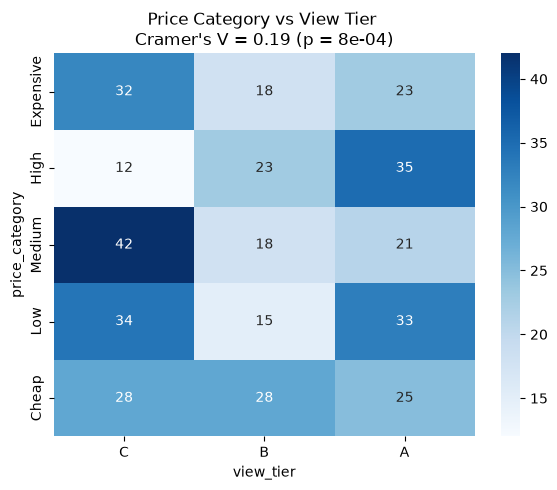


Price Category vs Purchase Tier: chi2=11.49, p=0.1754, Cramer's V=0.121


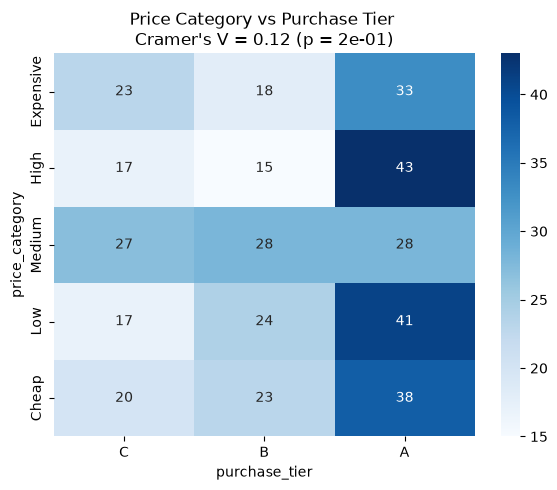


Price Category vs Revenue Tier: chi2=128.47, p=0.0000, Cramer's V=0.403


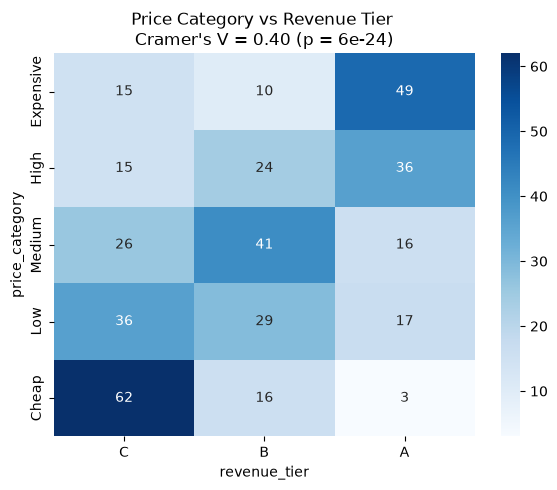

In [25]:
def contingency_check(df_original, col_1, col_2, col_1_order, col_2_order):
    df = df_original.copy()

    df = df[df[col_1].notna() & df[col_2].notna()]
    contingency = pd.crosstab(df[col_1], df[col_2])
    chi2, p, dof, expected = stats.chi2_contingency(contingency)
    n = contingency.sum().sum()
    cramers_v = np.sqrt(chi2 / (n * (min(contingency.shape) - 1)))

    print(f"\n{col_1.replace("_", " ").title()} vs {col_2.replace("_", " ").title()}: chi2={chi2:.2f}, p={p:.4f}, Cramer's V={cramers_v:.3f}")

    # Visualization Check 

    plt.figure(figsize=(6, 5))
    sns.heatmap(contingency.reindex(index=col_1_order, columns=col_2_order), annot=True, fmt="d", cmap="Blues")
    plt.title(f"{col_1.replace("_"," ").title()} vs {col_2.replace("_", " ").title()} \nCramer's V = {cramers_v:.2f} (p = {p:.0e})")
    plt.tight_layout()
    plt.savefig("tier_crosstab_heatmap.png", dpi=150)

    plt.show()

df = item_tiers.copy()

price_order = ['Expensive', 'High', 'Medium', 'Low', 'Cheap']
tier_order = ['C', 'B', 'A']
tiers = ['view_tier', 'purchase_tier', 'revenue_tier']
for tier in tiers:
    contingency_check(df, 'price_category', tier, price_order, tier_order)

### Basket Analysis

#### Load Data and Clean

In [26]:
# Load data and clean
def item_associations(raw_items, disp=False, use_filter=False):
    items_df = raw_items.copy()
    items_df = items_df[items_df['event_name'].eq('purchase')].reset_index(drop=True)
    items = items_df[['transaction_id', 'item_name']]
    n_before = len(items)
    items = items.drop_duplicates()
    n_after = len(items)
    if disp:
        print(f'{n_after} items remain out of {n_before} items after deduplicating.')
    items = items[~items['transaction_id'].eq('(not set)')]
    n_before, n_after = n_after, len(items)
    if disp:
        print(f'{n_after} item remain out of {n_before} items after dropping obfuscated data.')
    
    if use_filter:
        filter_out = [
            'Black', 'Blue', 'Red', 'Yellow', 'White', '(Blue/Green)', '(Multicolored)', '(Red/Yellow)', 'Charcoal', 'Coral',
            'Gray', 'Green', 'Grey', 'Ivory', 'Mint', 'Moss', 'Navy', 'Olive', 'Orange', 'Pink', "Grass", "Neon", "Light", 
            "Citron", "Lilac", "Cloud", "Confetti", "24 oz", "24oz"
        ]
        light_colours = ('Light ' + pd.Series(filter_out)).tolist()
        bright_colours = ('Bright ' + pd.Series(filter_out)).tolist()
        filter_out.extend(light_colours)
        filter_out.extend(bright_colours)
        pattern = r'\b(' + '|'.join(filter_out) + r')\b'
        items['item_name'] = items['item_name'].str.replace(pattern, '', case=False, regex=True).str.strip().str.replace('  ',' ')

    return items
items = item_associations(raw_items, disp=True)

13210 items remain out of 16003 items after deduplicating.
12934 item remain out of 13210 items after dropping obfuscated data.


#### One-Hot Encode the Basket

In [27]:
# One-hot basket dataframe (transactions x items) 
def one_hot_basket(raw_items, disp=False, use_item_filter=False):
    items = item_associations(raw_items, use_filter=use_item_filter)
    items['item_name'] = items['item_name'].str.strip()
    basket = pd.crosstab(items["transaction_id"], items["item_name"])
    basket = (basket > 0).astype(bool) 
    n_transactions = len(basket)
    if disp:
        print(f"{n_transactions} transactions across {basket.shape[1]} unique items")
        display(basket.head())
    return basket
basket = one_hot_basket(raw_items, disp=True)

4451 transactions across 390 unique items


item_name,#IamRemarkable Journal,#IamRemarkable Ladies T-Shirt,#IamRemarkable Lapel Pin,#IamRemarkable Pen,#IamRemarkable Tote,#IamRemarkable Unisex Hoodie,#IamRemarkable Unisex T-Shirt,#IamRemarkable Water Bottle,Android Buoy Bottle,Android Flex Journal White,...,YouTube Iconic Play Pin,YouTube Jotter Task Pad,YouTube Leather Strap Hat Black,YouTube Play Mug,YouTube Small Sticker Sheet,YouTube Standards Zip Hoodie Black,YouTube Transmission Journal Red,YouTube Twill Sandwich Cap Black,YouTube Women's Favorite Tee White,Youth Jumbo Print Tee White
transaction_id,,,,,,,,,,,,,,,,,,,,,
100659,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
100953,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
101047,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
101328,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
101412,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False


#### Pair-wise Basket Analysis

In [28]:
def basket_analysis(basket_df: pd.DataFrame, items: list) -> pd.DataFrame:
    basket_np = basket_df.astype(int).to_numpy()
    transactions = basket_np.T @ basket_np # Pairwise transaction number
    support = transactions / np.shape(basket_np)[0]  # Probability of transaction for pairwise items.
    confidence = (transactions) / np.diag(transactions) # confidence.

    D = np.diag(support) * np.eye(np.shape(support)[0]) # Diagonal matrix.
    D_inv = np.linalg.inv(D) # Inverse the diagonal matrix.
    lifts = (D_inv @ support) @ D_inv # Normalize the support to get lift.

    # Create a new dataframe with Basket: prod1-prod2, support prod1-prod2, confidence prod1, confidence prod2, lift
    basket = []
    transaction = []
    support_basket = []
    confidence_of_first_item = []
    confidence_of_second_item = []
    lift = []
    antecedent = []
    consequent = []
    is_self_node = []
    for i in range(0, np.shape(basket_np)[0]):
        for j in range(0, np.shape(basket_np)[1]):
            if (i > j) or (items[i] == '(not set)' or items[j] == '(not set)'):
                continue
            
            if (i == j):
                basket.append(f"{items[i]}")
                is_self_node.append(1)
            else:
                basket.append(f"{items[i]} - {items[j]}")
                is_self_node.append(0)

            antecedent.append(f"{items[i]}")
            consequent.append(f"{items[j]}")
            transaction.append(transactions[i,j])
            support_basket.append(support[i,j])
            confidence_of_first_item.append(confidence[i,j])
            confidence_of_second_item.append(confidence[j,i])
            lift.append(lifts[i,j])

    basket_analysis_df = pd.DataFrame({'antecedent': antecedent,
                                       'consequent': consequent,
                                        'basket': basket,
                                        'number_of_transactions': transaction,
                                        'support_of_basket': support_basket,
                                        'confidence_of_first_item': confidence_of_first_item,
                                        'confidence_of_second_item': confidence_of_second_item,
                                        'lift': lift,
                                        'is_self_node': is_self_node})
    return basket_analysis_df

basket_analysis_df = basket_analysis(basket,basket.columns.tolist())

#### Calculate the value of the item pair basket

In [29]:
def get_basket_value(basket_df: pd.DataFrame, items_df: pd.DataFrame, item_pairs_df) -> pd.DataFrame:
    basket_analysis_df = item_pairs_df.copy()
    new_basket = basket_df.merge(items_df[['transaction_id', 'price']], on='transaction_id', how='left')

    basket_value = []
    for _, row in basket_analysis_df.iterrows():
        basket_value.append({
            'basket_value': new_basket[new_basket[row['antecedent']].eq(True) & new_basket[row['consequent']].eq(True)]['price'].mean(),
            'antecedent': row['antecedent'],
            'consequent': row['consequent']
            })

    basket_value = pd.DataFrame(basket_value)
    basket_analysis_df = basket_analysis_df.merge(basket_value, on =['antecedent', 'consequent'], how='left')
    return basket_analysis_df

basket_analysis_df = get_basket_value(basket, raw_items, basket_analysis_df)

#### Plot histogram to check distribution of support

In [30]:
# Initialize functions
def plot_log(df, col, n_bins=20, format = None, prec=0, title="Histogram (log-spaced bins)", xlabel = 'column', ylabel='counts', yscale='linear'):
    data = df[col].dropna()
    counts, edges = log_space_bins(data, n_bins)
    if format == 'timestamp':
        labels = [f"{fmt(edges[i])}\u2013{fmt(edges[i + 1])}" for i in range(len(edges) - 1)]
    elif format == 'value':
        labels = [f"${np.int16(np.round(edges[i],0))} - ${np.int16(np.round(edges[i + 1],0))}" for i in range(len(edges) - 1)]
    else:
        labels = [f"{np.round(edges[i],prec)} - {np.round(edges[i + 1],prec)}" for i in range(len(edges) - 1)]

    # Plot
    fig = go.Figure(go.Bar(x=labels, y=counts))
    fig.update_layout(
        title=title,
        xaxis_title=xlabel,
        yaxis=dict(
            type=yscale,
            title=ylabel
        ),
        bargap=0.1,
    )
    fig.show()
    return edges,counts,labels

# Log-spaced bin edges 
def log_space_bins(data, n_bins):
    log_min, log_max = np.log1p(data.min()), np.log1p(data.max()) #log1p deals with 0 values
    log_edges = np.linspace(log_min, log_max, n_bins + 1)
    edges = np.expm1(log_edges)  # back to original duration units

    edges[0] = data.min()
    edges[-1] = data.max()

    counts, _ = np.histogram(data, bins=edges)
    return counts, edges

# bin labels
def fmt(hours):
    if hours < 1:
        return f"{hours * 60:.0f}m"
    if hours < 48:
        return f"{hours:.0f}h"
    return f"{hours / 24:.0f}d"


print(f"Minimum: {basket_analysis_df['support_of_basket'].min()}")
print(f"Median: {basket_analysis_df['support_of_basket'].median()}")
print(f"Maximum: {basket_analysis_df['support_of_basket'].max()}")
plot_log(
    basket_analysis_df,
    'support_of_basket',
    format='',
    prec=3,
    n_bins=7,
    yscale='log'
)

print(f"Total number of transactions: {len(basket)}")
print(f"\nTop 20 single items:")
df_plot = basket_analysis_df.sort_values('number_of_transactions', ascending=False)[0:20]
df_plot = df_plot.sort_values('number_of_transactions')
fig = px.bar(df_plot, x='number_of_transactions', y='basket', orientation='h')
fig.show()

print(f"\nTop 20 pair-items:")
df_plot = basket_analysis_df[basket_analysis_df['basket'].str.contains(' - ')].sort_values('number_of_transactions', ascending=False)[0:20]
df_plot = df_plot.sort_values('number_of_transactions')
fig = px.bar(df_plot, x='number_of_transactions', y='basket', orientation='h')
fig.show()


Minimum: 0.0
Median: 0.0
Maximum: 0.049651763648618286


Total number of transactions: 4451

Top 20 single items:



Top 20 pair-items:


Most support values are 0 - 0.001, let us put the threshold at 0.002 since this captures a good amount of basket pairs.

In [31]:
def style_basket_analysis(df):
    return (df.style
        .background_gradient(cmap='Purples', subset=['support_of_basket'])
        .background_gradient(cmap='Blues', subset=['confidence_of_first_item'])
        .background_gradient(cmap='Greens', subset=['confidence_of_second_item'])
        .background_gradient(cmap='YlOrRd', subset=['lift'])
        .format({
            'support_of_basket': '{:.2%}',
            'confidence_of_first_item': '{:.2%}',
            'confidence_of_second_item': '{:.2%}',
            'lift': '{:.2f}',
            'basket_value': '{:.0f}'
        })
    )

pairwise_item_analysis_df = basket_analysis_df[basket_analysis_df['basket'].str.contains(' - ')]
high_confidence_basket = pairwise_item_analysis_df[pairwise_item_analysis_df['support_of_basket'].gt(0.002) & (pairwise_item_analysis_df['confidence_of_first_item'].gt(0.30) | pairwise_item_analysis_df['confidence_of_second_item'].gt(0.30))].sort_values('support_of_basket',ascending=False).reset_index(drop=True)
high_confidence_basket = high_confidence_basket[['basket', 'support_of_basket', 'confidence_of_first_item', 'confidence_of_second_item', 'lift', 'basket_value']]
style_basket_analysis(high_confidence_basket[0:10])

,basket,support_of_basket,confidence_of_first_item,confidence_of_second_item,lift,basket_value
0,Google Light Pen Blue - Google Light Pen Red,0.88%,60.00%,46.99%,32.18,9
1,Google Light Pen Green - Google Light Pen Red,0.85%,58.46%,67.86%,46.47,9
2,Google Light Pen Blue - Google Light Pen Green,0.79%,62.50%,42.17%,33.52,9
3,Android Large Removable Sticker Sheet - Android SM S/F18 Sticker Sheet,0.61%,27.84%,57.45%,26.36,9
4,Google Crew Combed Cotton Sock - Google Crew Socks,0.58%,20.47%,32.50%,11.39,14
5,Google Clear Framed Blue Shades - Google Clear Framed Yellow Shades,0.52%,60.53%,47.92%,56.13,7
6,Google Pen Bright Blue - Google Pen Grass Green,0.49%,81.48%,47.83%,78.84,7
7,Google PNW Campus Mug - Google Seattle Campus Mug,0.47%,36.21%,38.18%,29.30,8
8,Google Cambridge Campus Mug - Google NYC Campus Mug,0.45%,24.39%,48.78%,26.48,8
9,Google Pen Bright Blue - Google Pen Neon Coral,0.40%,60.00%,39.13%,58.06,7


Many of the bought-together items are the same product but in a different colour. Let us filter out these colours to clearly bring out what distinct items are bought together.

In [32]:
basket = one_hot_basket(raw_items, disp=False, use_item_filter=True)
basket_analysis_df = basket_analysis(basket, basket.columns.tolist())
basket_analysis_df = get_basket_value(basket, raw_items, basket_analysis_df)
pairwise_item_analysis_df = basket_analysis_df[basket_analysis_df['basket'].str.contains(' - ')]
high_confidence_basket = pairwise_item_analysis_df[pairwise_item_analysis_df['support_of_basket'].ge(0.002) & (pairwise_item_analysis_df['confidence_of_first_item'].ge(0.30) | pairwise_item_analysis_df['confidence_of_second_item'].ge(0.30))].sort_values(['confidence_of_first_item', 'confidence_of_second_item'], ascending=[False, False]).reset_index(drop=True)
high_confidence_basket = high_confidence_basket[['basket', 'support_of_basket', 'confidence_of_first_item', 'confidence_of_second_item', 'lift', 'basket_value']]
most_frequent_basket = pairwise_item_analysis_df[pairwise_item_analysis_df['support_of_basket'].ge(0.002)].sort_values('support_of_basket', ascending=False).reset_index(drop=True)
most_frequent_basket = most_frequent_basket[['basket', 'support_of_basket', 'confidence_of_first_item', 'confidence_of_second_item', 'lift', 'basket_value']]

print("High Confidence Item Pairs:")
display(style_basket_analysis(high_confidence_basket[0:10]))

print("Most Freqent Item Pairs Bought Together:")
display(style_basket_analysis(most_frequent_basket[0:10]))

print(f"Total number of transactions: {len(basket)}")
print(f"\nTop 20 single items:")
df_plot = basket_analysis_df.sort_values('number_of_transactions', ascending=False)[0:20]
df_plot = df_plot.sort_values('number_of_transactions')
fig = px.bar(df_plot, x='number_of_transactions', y='basket', orientation='h')
fig.show()

print(f"\nTop 20 pair-items:")
df_plot = pairwise_item_analysis_df.sort_values('number_of_transactions', ascending=False)[0:20]
df_plot = df_plot.sort_values('number_of_transactions')
fig = px.bar(df_plot, x='number_of_transactions', y='basket', orientation='h')
fig.show()


High Confidence Item Pairs:


,basket,support_of_basket,confidence_of_first_item,confidence_of_second_item,lift,basket_value
0,Google Austin Campus Mug - Google Austin Campus Tote,0.25%,64.71%,15.28%,40.00,10
1,Google Cambridge Campus Mug - Google Cambridge Campus Sticker,0.20%,50.00%,21.95%,54.28,6
2,Google Pen - Maze Pen,0.43%,43.18%,6.23%,6.30,8
3,Google Crew Socks - Google Mural Socks,0.38%,39.53%,13.39%,13.86,14
4,Google Lapel Pin - Google Maps Pin,0.20%,39.13%,23.68%,45.83,15
5,Google PNW Campus Mug - Google Seattle Campus Mug,0.47%,36.21%,38.18%,29.30,8
6,Google LA Campus Mug - Google LA Campus Sticker,0.29%,36.11%,25.00%,30.91,8
7,Google See-No Hear-No Set - Google Slim Task Pad,0.20%,34.62%,21.43%,36.68,10
8,Google Pen - Google Recycled Pen,0.36%,33.33%,5.25%,4.86,10
9,Google NYC Campus Mug - Google NYC Campus Sticker,0.27%,30.77%,14.63%,16.70,9


Most Freqent Item Pairs Bought Together:


,basket,support_of_basket,confidence_of_first_item,confidence_of_second_item,lift,basket_value
0,Google Metallic Notebook Set - Google Pen,0.92%,13.44%,34.17%,4.99,9
1,Google Laptop and Cell Phone Stickers - Google Pen,0.76%,11.15%,26.77%,3.91,9
2,Google Heathered Pom Beanie - Google Speckled Beanie,0.76%,26.15%,20.00%,6.85,15
3,Google Clear Pen 4-Pack - Google Pen,0.70%,10.16%,24.60%,3.59,8
4,Android Large Removable Sticker Sheet - Android SM S/F18 Sticker Sheet,0.61%,27.84%,57.45%,26.36,9
5,Google Crew Combed Cotton Sock - Google Crew Socks,0.58%,20.47%,32.50%,11.39,14
6,Google Badge Heavyweight Pullover - Google Crewneck Sweatshirt,0.58%,6.79%,17.33%,2.01,33
7,Google Camp Mug - Google Pen,0.58%,8.52%,9.56%,1.39,10
8,Google Camp Mug - Google Flat Front Bag,0.54%,29.63%,8.82%,4.85,17
9,Google Clear Pen 4-Pack - Google Metallic Notebook Set,0.54%,20.00%,19.05%,7.07,8


Total number of transactions: 4451

Top 20 single items:



Top 20 pair-items:


#### Basket Analysis to Graph

In [33]:
import networkx as nx
import plotly.graph_objects as go
import random

G = nx.DiGraph()

basket_analysis_df
high_confidence_basket = pairwise_item_analysis_df[pairwise_item_analysis_df['support_of_basket'].ge(0.002) & (pairwise_item_analysis_df['confidence_of_first_item'].ge(0.20) | pairwise_item_analysis_df['confidence_of_second_item'].ge(0.20))].sort_values(['confidence_of_first_item', 'confidence_of_second_item'], ascending=[False, False]).reset_index(drop=True)
for _, row in high_confidence_basket.iterrows():
    # Split the basket string into the 'From' item and 'To' item
    items = [item.strip() for item in row['basket'].split('-')]
    if len(items) == 2:
        source_item, target_item = items[0], items[1]
        
        # Add the directional association edge with metrics
        G.add_edge(
            source_item, 
            target_item, 
            lift=row['lift'],
            transactions=row['number_of_transactions']
        )

detected_communities = nx.community.louvain_communities(G, seed=42)
high_confidence_basket['community'] = pd.NA
for community_assignment, community in enumerate(detected_communities):
    high_confidence_basket.loc[
        high_confidence_basket['consequent'].isin(list(community)) | high_confidence_basket['antecedent'].isin(list(community)), 'community'
    ] = community_assignment
            
            
            
high_confidence_basket
temp = basket_analysis_df.merge(high_confidence_basket[['basket', 'community']], on='basket', how='left')



#### Basket Analysis Network Plot

In [34]:
# Community detection to cluster connected nodes together
detected_communities = nx.community.louvain_communities(G, seed=42)

node_community_map = {}
community_groups = {}
for comm_idx, node_set in enumerate(detected_communities):
    community_groups[comm_idx] = sorted(list(node_set))
    for node in node_set:
        node_community_map[node] = comm_idx

# Generate concentric circles + jitter
pos = {}
num_communities = len(community_groups)
MACRO_RADIUS = 5.0        # Radial distance between separated item communities
INTERNAL_RADIUS_BASE = 0.8 # Internal cluster radius
JITTER_AMOUNT = 1.2      # y-jitter so nodes are not on the same y-value

for comm_idx, nodes in community_groups.items():
    num_nodes = len(nodes)
    if num_nodes == 0:
        continue
    
    macro_angle = (2 * np.pi * comm_idx) / num_communities
    center_x = MACRO_RADIUS * np.cos(macro_angle)
    center_y = MACRO_RADIUS * np.sin(macro_angle)
    
    internal_radius = INTERNAL_RADIUS_BASE + (num_nodes * 0.05)
    
    for node_idx, node in enumerate(nodes):
        internal_angle = (2 * np.pi * node_idx) / num_nodes if num_nodes > 1 else 0
        local_x = internal_radius * np.cos(internal_angle)
        local_y = internal_radius * np.sin(internal_angle)
        
        # Jitter effect
        jitter_x = random.uniform(-JITTER_AMOUNT, JITTER_AMOUNT)
        jitter_y = random.uniform(-JITTER_AMOUNT, JITTER_AMOUNT)
        
        pos[node] = (center_x + local_x + jitter_x, center_y + local_y + jitter_y)

# Extract antecedent sets for mapping node color traces
from_nodes = set(u for u, v in G.edges())

edge_x, edge_y = [], []
mid_x, mid_y, mid_hover = [], [], []

for u, v, d in G.edges(data=True):
    x0, y0 = pos[u]
    x1, y1 = pos[v]
    
    # Standard continuous edge drawing line array
    edge_x.extend([x0, x1, None])
    edge_y.extend([y0, y1, None])
    
    # Calculate structural midpoints between nodes
    mx = (x0 + x1) / 2
    my = (y0 + y1) / 2
    mid_x.append(mx)
    mid_y.append(my)
    mid_hover.append(f"<b>Association Rule:</b><br>{u} ➔ {v}<br><br><b>Lift:</b> {d['lift']}<br><b>Transactions:</b> {d['transactions']}")


edge_trace = go.Scatter(
    x=edge_x, y=edge_y,
    line=dict(width=1.5, color='rgba(160, 160, 160, 0.5)'),
    hoverinfo='skip',
    mode='lines'
)

edge_hover_trace = go.Scatter(
    x=mid_x, y=mid_y,
    mode='markers',
    hoverinfo='text',
    text=mid_hover,
    marker=dict(
        size=12,
        color='rgba(0,0,0,0)', # Completely invisible marker
        opacity=0
    )
)

# Map Nodes into red and blue category pools
from_x, from_y, from_hover = [], [], []
to_x, to_y, to_hover = [], [], []

for node in G.nodes():
    x, y = pos[node]
    comm_id = node_community_map[node]
    hover_str = f"Product: {node}<br>Market Cluster: {comm_id}<br>Degree: {G.degree(node)}"
    
    if node in from_nodes:
        from_x.append(x)
        from_y.append(y)
        from_hover.append(hover_str)
    else:
        to_x.append(x)
        to_y.append(y)
        to_hover.append(hover_str)

annotations = []
for node in G.nodes():
    x, y = pos[node]
    # Truncate Google string to avoid overlapping text layouts
    short_label = node.replace("Google ", "")
    annotations.append(
        dict(
            x=x, y=y-0.25,
            yanchor='top',
            text=f"<b>{short_label}</b>",
            showarrow=False,
            font=dict(color='#1A1A1A', size=7),
            bgcolor='rgba(255, 255, 255, 0.95)',
            bordercolor='rgba(200, 200, 200, 0.8)',
            borderwidth=1,
            borderpad=3,
        )
    )

from_trace = go.Scatter(
    x=from_x, y=from_y, mode='markers', hoverinfo='text', text=from_hover,
    marker=dict(size=28, color="#66B2E8", line=dict(width=2, color='white'))
)

to_trace = go.Scatter(
    x=to_x, y=to_y, mode='markers', hoverinfo='text', text=to_hover,
    marker=dict(size=28, color="#E98E8E", line=dict(width=2, color='white'))
)


fig = go.Figure(
    data=[edge_trace, edge_hover_trace, from_trace, to_trace],
    layout=go.Layout(
        title='Basket Association Network (Blue=Antecedent, Red=Consequent)',
        showlegend=False,
        hovermode='closest',
        margin=dict(b=40, l=40, r=40, t=60),
        xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
        yaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
        annotations=annotations,
        height=1200,
        width=1200
    )
)

fig.show()

import plotly.io as pio

# Assuming 'fig' is your existing Plotly figure object
# Using 'cdn' keeps the text small by fetching the Plotly engine online
html_string = pio.to_html(fig, full_html=False, include_plotlyjs='cdn')

# Print the raw string to copy it
#print(html_string)

#fig.write_html(r"Basket_Association_Network.html", include_plotlyjs="cdn")

### User Journey: Session-level to User-level Scope

In [35]:
def get_hoursbefore(timestamps):
    conversion_timestamp = timestamps[-1]
    hours_before = np.array([(conversion_timestamp - touch_timestamp) / pd.Timedelta(hours=1) for touch_timestamp in timestamps])
    return hours_before

df = sessions[['user_pseudo_id', 'session_id', 'session_start', 'session_date', 'channel', 'converted', 'revenue']]

journeys = (df
    .sort_values(['user_pseudo_id', 'session_start'])
    .groupby('user_pseudo_id')
    .agg(    
        sessions = ('session_id', list),
        conversion_path = ('channel', list),
        touchpoints = ('channel', 'count'),
        journey_start = ('session_date', 'first'),
        journey_end = ('session_date', 'last'),
        channel_set = ('channel', set), # For Shapley Value attribution model.
        timestamp_path = ('session_start', list),
        conversion_count = ('converted', 'sum'),
        conversion_value_usd = ('revenue', 'sum')
    )
)

journeys['has_conversion'] = journeys['conversion_count'] > 0
journeys['touchpoints'] = journeys['sessions'].apply(lambda x: len(x))
journeys['hours_before'] = journeys['timestamp_path'].apply(lambda x: get_hoursbefore(x))
journeys['duration'] = journeys['hours_before'].apply(lambda x: x[0])


converting = journeys[journeys['has_conversion']]
display(converting.head())

,sessions,conversion_path,touchpoints,journey_start,journey_end,channel_set,timestamp_path,conversion_count,conversion_value_usd,has_conversion,hours_before,duration
user_pseudo_id,,,,,,,,,,,,
10092926.3786306416,[10092926.3786306416-10092926.3786306416-80149...,"[Organic Search, Direct]",2,2021-01-22,2021-01-22,"{Organic Search, Direct}","[2021-01-22 05:23:36.291786+00:00, 2021-01-22 ...",1,89.0,True,"[14.62168142888889, 0.0]",14.621681
10111055.8768683862,[10111055.8768683862-10111055.8768683862-69759...,[Referral],1,2020-12-10,2020-12-10,{Referral},[2020-12-10 12:18:55.718750+00:00],1,94.0,True,[0.0],0.000000
1014825.0200289249,[1014825.0200289249-1014825.0200289249-2716419...,"[Referral, Unclassified]",2,2020-11-03,2020-11-03,"{Referral, Unclassified}","[2020-11-03 07:44:47.992214+00:00, 2020-11-03 ...",1,184.0,True,"[2.3777268872222224, 0.0]",2.377727
1016446.8237887674,[1016446.8237887674-1016446.8237887674-9359060...,"[Referral, Organic Search, Organic Search, Org...",4,2020-12-21,2021-01-16,"{Referral, Organic Search}","[2020-12-21 09:27:19.639574+00:00, 2020-12-21 ...",1,85.0,True,"[618.7117723227777, 616.6664090636111, 602.265...",618.711772
10172849.5375293351,[10172849.5375293351-10172849.5375293351-49745...,"[Referral, Unclassified, Direct]",3,2020-12-09,2020-12-12,"{Referral, Unclassified, Direct}","[2020-12-09 07:14:24.354453+00:00, 2020-12-09 ...",1,155.0,True,"[81.77419622083333, 80.57441011638889, 0.0]",81.774196


### Top Conversion Channel Paths

##### Change Conversion Path List to Conversion Path String

In [ ]:
def pathing(lst):
    if len(lst) == 1:
        return str(lst[0])
    elif len(lst) == 2:
        return str(lst[0]) + " > " + str(lst[1])
    
    else:
        path = ''
        for i in range(0, len(lst)):
            if i == len(lst) - 1:
                path += str(lst[i])
                continue
            path += str(lst[i]) + " > "
    return path

converting['hours_path'] = converting['hours_before'].apply(lambda x: pathing(np.int16(np.round(x,0))))
converting['path_to_conversion'] = converting['conversion_path'].apply(pathibng)
converting['conversion_value_usd'] = converting['conversion_value_usd'].replace(0, np.nan)
user_paths = converting.reset_index()[['user_pseudo_id', 'sessions', 'journey_start', 'journey_end', 'path_to_conversion', 'channel_set', 'conversion_count', 'hours_path', 'duration', 'conversion_value_usd']]
user_paths['touchpoints'] = user_paths['sessions'].apply(lambda x: len(x))

display(user_paths.head())

,user_pseudo_id,sessions,journey_start,journey_end,path_to_conversion,channel_set,conversion_count,hours_path,duration,conversion_value_usd,touchpoints
0,10092926.3786306416,[10092926.3786306416-10092926.3786306416-80149...,2021-01-22,2021-01-22,Organic Search > Direct,"{Organic Search, Direct}",1,15 > 0,14.621681,89.0,2
1,10111055.8768683862,[10111055.8768683862-10111055.8768683862-69759...,2020-12-10,2020-12-10,Referral,{Referral},1,0,0.000000,94.0,1
2,1014825.0200289249,[1014825.0200289249-1014825.0200289249-2716419...,2020-11-03,2020-11-03,Referral > Unclassified,"{Referral, Unclassified}",1,2 > 0,2.377727,184.0,2
3,1016446.8237887674,[1016446.8237887674-1016446.8237887674-9359060...,2020-12-21,2021-01-16,Referral > Organic Search > Organic Search > O...,"{Referral, Organic Search}",1,619 > 617 > 602 > 0,618.711772,85.0,4
4,10172849.5375293351,[10172849.5375293351-10172849.5375293351-49745...,2020-12-09,2020-12-12,Referral > Unclassified > Direct,"{Referral, Unclassified, Direct}",1,82 > 81 > 0,81.774196,155.0,3


#### Journey Duration Distribution

In [37]:
# Descriptive stats
print(f'Minimum: {np.int16(np.round(np.min(user_paths['duration']),0))} hrs')
print(f'Median: {np.int16(np.round(np.median(user_paths['duration']),0))} hrs')
print(f'Maximum: {np.int16(np.round(np.max(user_paths['duration']),0))} hrs')

edges, counts, labels = plot_log(user_paths, 
                                'duration', 
                                title="Journey Duration (log-spaced bins)", 
                                xlabel="Duration", 
                                ylabel="Journeys",
                                format='timestamp')


def add_count_label_column(df_original: pd.DataFrame, col: str, name: str, edges: list[float], counts: list[int], labels: list[str]) -> pd.DataFrame:
    df = df_original.copy()
    df[f'{name}_counts'] = pd.NA
    df[f'{name}_bins'] = pd.NA
    for i in range(1,len(edges)):
        df.loc[df[col].ge(edges[i-1]) & df[col].lt(edges[i]), f'{name}_count'] = counts[i-1]
        df.loc[df[col].ge(edges[i-1]) & df[col].lt(edges[i]), f'{name}_bins'] = labels[i-1]

    return df

user_paths = add_count_label_column(user_paths, 'duration', 'duration', edges, counts, labels)

Minimum: 0 hrs
Median: 82 hrs
Maximum: 2154 hrs


Most users convert immediately and evidently on their first session (a session is defined as the amount of time a user spends on the site between $0$ to $30$ minutes). The second largest number of converted journeys occurs when the user spends between $20$ days to $30$ days. Anything longer than a month decreases the odds and anything less than 20 days decreases the odds, except for immediate purchases.

#### Journey Revenue Distribution


In [38]:
# Descriptive stats
print(f'Minimum: {np.int16(np.round(np.min(user_paths['duration']),0))} hrs')
print(f'Median: {np.int16(np.round(np.median(user_paths['duration']),0))} hrs')
print(f'Maximum: {np.int16(np.round(np.max(user_paths['duration']),0))} hrs')

edges, counts, labels = plot_log(user_paths, 
         'conversion_value_usd',
         title="Journey Conversion Value (log-spaced bins)",
         xlabel="Conversion Value (USD)",
         ylabel="Journeys",
         format='value')

user_paths = add_count_label_column(user_paths, 'conversion_value_usd', 'revenue', edges, counts, labels)

Minimum: 0 hrs
Median: 82 hrs
Maximum: 2154 hrs


Revenue is very clearly log-normal distributed. Most of the revenue comes from users spending between $\$33$ and $\$88$.

##### Quick Test on Log-Normality (Supplementary)

Raw duration:    skew=4.81, kurtosis=36.75
log1p(duration): skew=0.13, kurtosis=0.21
(closer to 0 after the transform = evidence the log scale is a better fit)

n = 4066
Shapiro-Wilk:      W=0.9978, p=1.302e-05


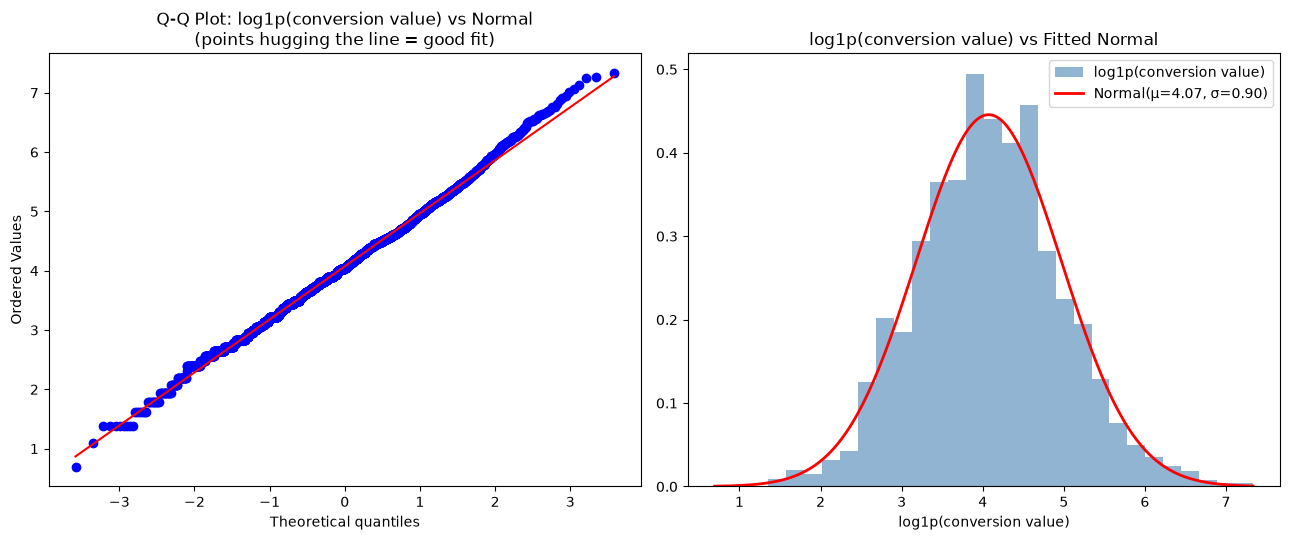

In [39]:
conversion_value = user_paths["conversion_value_usd"].dropna()
log_conversion_value = np.log1p(conversion_value)

print(f"Raw duration:    skew={stats.skew(conversion_value):.2f}, kurtosis={stats.kurtosis(conversion_value):.2f}")
print(f"log1p(duration): skew={stats.skew(log_conversion_value):.2f}, kurtosis={stats.kurtosis(log_conversion_value):.2f}")
print("(closer to 0 after the transform = evidence the log scale is a better fit)")

# Normality test on log-transformed data
n = len(log_conversion_value)
print(f"\nn = {n}")

# Shapiro-Wilk normality test after log-transform
stat, p = stats.shapiro(log_conversion_value)
print(f"Shapiro-Wilk:      W={stat:.4f}, p={p:.4g}")

# Visual check
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

stats.probplot(log_conversion_value, dist="norm", plot=axes[0])
axes[0].set_title("Q-Q Plot: log1p(conversion value) vs Normal\n(points hugging the line = good fit)")

mu, sigma = log_conversion_value.mean(), log_conversion_value.std()
x = np.linspace(log_conversion_value.min(), log_conversion_value.max(), 200)
axes[1].hist(log_conversion_value, bins=30, density=True, alpha=0.6, color="steelblue",
             label="log1p(conversion value)")
axes[1].plot(x, stats.norm.pdf(x, mu, sigma), "r-", lw=2,
             label=f"Normal(\u03bc={mu:.2f}, \u03c3={sigma:.2f})")
axes[1].set_title("log1p(conversion value) vs Fitted Normal")
axes[1].set_xlabel("log1p(conversion value)")
axes[1].legend()

fig.tight_layout()
fig.savefig("log_normality_check.png", dpi=150)
plt.show()

#### Aggregate the same paths

In [40]:
paths = user_paths.groupby('path_to_conversion').agg(
    count = ('hours_path', 'count'),
    mean_journey_time = ('duration', 'mean'),
    mean_conversion_value = ('conversion_value_usd', 'mean'),
).sort_values('count',ascending=False).reset_index().reset_index()

paths['index'] = '#'+(paths['index'] + 1).astype(str)
paths['representation'] = (paths['count'] / paths['count'].sum() * 100).round(2).astype(str) + '%'
paths['mean_conversion_value'] = '$'+paths['mean_conversion_value'].round(2).astype(str)
paths['mean_journey_time'] = paths['mean_journey_time'].round(0).astype(int).astype(str) + ' hrs'
top_paths = (paths[['index', 'path_to_conversion', 'count', 'representation', 'mean_conversion_value', 'mean_journey_time']]
    .rename(
        columns={
            'index': 'Rank',
            'path_to_conversion': 'Converting Path',
            'count': 'Occurences (QTD)',
            'representation': 'Representation (%)',
            'mean_conversion_value': 'Mean Conversion Value (USD)',
            'mean_journey_time': 'Mean Journey Time (hr)',
        }
    )
)
display(top_paths.head(10))


,Rank,Converting Path,Occurences (QTD),Representation (%),Mean Conversion Value (USD),Mean Journey Time (hr)
0,#1,Organic Search,493,12.12%,$63.59,0 hrs
1,#2,Referral,244,6.0%,$69.02,0 hrs
2,#3,Direct,154,3.79%,$57.16,0 hrs
3,#4,Organic Search > Direct,124,3.05%,$67.6,55 hrs
4,#5,Organic Search > Organic Search,90,2.21%,$72.81,136 hrs
5,#6,Direct > Direct,81,1.99%,$72.4,110 hrs
6,#7,Organic Search > Unclassified,74,1.82%,$80.89,75 hrs
7,#8,Referral > Unclassified,56,1.38%,$78.05,84 hrs
8,#9,Direct > Direct > Direct,55,1.35%,$88.35,195 hrs
9,#10,Unclassified,55,1.35%,$63.8,0 hrs


- Most occurring path is a single Organic Search, in which the purchase is immediate. 

- Immediate paths also occur the most.

#### Attribution Modeling

In [45]:
# =============== Heuristic models ==================

# Attribution dataframer
def attribution_model(records, name):
    df = pd.DataFrame(records)
    return (df
    .groupby('channel')['value']
    .sum()
    .reset_index()
    .rename(columns={'value': name})
    .set_index('channel')
    )

# Position-Based (U-Shaped) Attribution Model
def position_based(touch: int, n: int) -> int | float:
    if touch == 0 or touch == (n - 1): # first touch-point or last touch-point
        if n == 1:
            return 1
        if n == 2:
            return 0.5
        return 0.4
    return 0.2 / (n - 2) # Split evenly across the middle touches


        
# Time-Decay Attribution Model
def time_decay(timestamps):
    # Initialize Parameters
    half_life = 168 # 7 day half-life.
    decay_rate = np.log(2) / half_life

    hours_before = get_hoursbefore(timestamps)
    weights = np.exp(-1 * hours_before * decay_rate) # Exponential decay.
    weights /= weights.sum() # Normalize to ensure weights are in the range [0, 1].
    return weights

# Calculate each heuristic attribution model

first_click_records = []
last_click_records = []
last_click_non_direct_records = []
linear_records = []
position_records = []
time_decay_records = []
for _, row in converting.iterrows():
    n = len(row['conversion_path']) # Number of touchpoints for the journey
    weights = time_decay(row['timestamp_path']) # Time-decay weights
    single_credit = 1
    uniform_credit_per_touch = 1 / n
    single_value = row['conversion_value_usd'] # The revenue made in the journey
    uniform_value_per_touch = row['conversion_value_usd'] / n # Uniformly distributed credits based on the number of touchpoints.
    session_ids = row['sessions']
    for touch, ch in enumerate(row['conversion_path']):
        if touch == 0: # First touch
            first_click_records.append({'session_id': session_ids[touch], 'channel': ch, 'credit': single_credit, 'value': single_value})
        if touch == n - 1: # Last touch
            last_click_records.append({'session_id': session_ids[touch], 'channel': ch, 'credit': single_credit, 'value': single_value})
        if ch != 'Direct': # Store temporarily the non-direct channels as a single credit. 
            last_click_non_direct = {'session_id': session_ids[touch], 'channel': ch, 'credit': single_credit, 'value': single_value}
        linear_records.append({'session_id': session_ids[touch], 'channel': ch, 'credit': uniform_credit_per_touch, 'value': uniform_value_per_touch})
        pos = position_based(touch, n)
        position_records.append({'session_id': session_ids[touch], 'channel': ch, 'credit': pos * single_credit, 'value': pos * single_value})
        weight = weights[touch]
        time_decay_records.append({'session_id': session_ids[touch],'channel': ch, 'credit': weight * single_credit, 'value': weight * single_value})
    last_click_non_direct_records.append(last_click_non_direct)

# Convert dictionary to dataframe
first_click_attr = attribution_model(first_click_records, 'First-Click')
last_click_attr = attribution_model(last_click_records, 'Last-Click')
linear_attr = attribution_model(linear_records, 'Linear')        
position_attr = attribution_model(position_records, 'Position-Based')
time_decay_attr = attribution_model(time_decay_records, 'Time-Decay')
last_click_non_direct_attr = attribution_model(last_click_non_direct_records, 'Last-Click Non-Direct')

# Put all models into a single dataframe
attribution_models = pd.concat([
    first_click_attr, 
    last_click_attr, 
    linear_attr,
    position_attr, 
    time_decay_attr, 
    last_click_non_direct_attr
], axis=1).fillna(0).round(2)


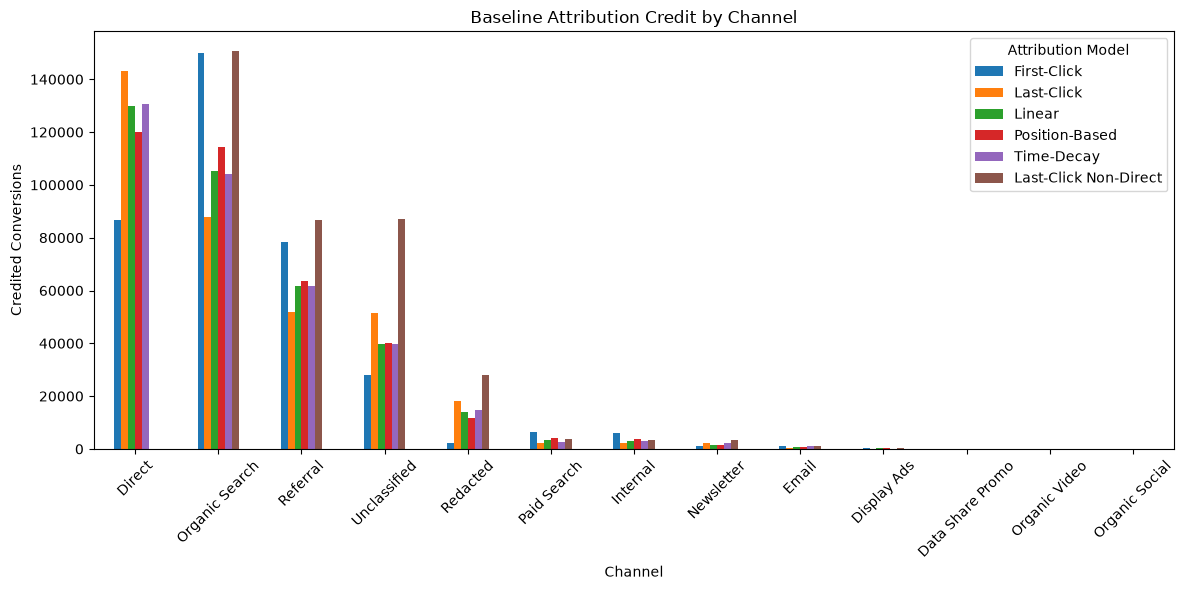

In [46]:
# Plot the attribution models
df = attribution_models.copy()
df['medians'] = df.median(axis=1)
df = df.sort_values('medians', ascending=False).drop(columns='medians')
#df = df[df.median(axis=1).sort_values(ascending=False).index.values]
df.plot(kind='bar', figsize=(12,6))

plt.title("Baseline Attribution Credit by Channel")
plt.ylabel("Credited Conversions")
plt.xlabel("Channel")
plt.xticks(rotation=45)
plt.legend(title="Attribution Model")
plt.tight_layout()
plt.show()

### Algorithmic Models

#### Shapely Values

In [47]:
import itertools

def shapely(df: pd.DataFrame, channels: list, col_set: set, col_value: int | float) -> pd.DataFrame:
    P = set(channels)
    # Create a hashmap of each subset:
    results_dict: dict[frozenset] = dict()
    P_n = len(P)
    for i in range(1, P_n + 1):
        for combo in itertools.combinations(P, i):
            results_dict[frozenset(combo)] = 0

    # Populate the hashmap with the total revenues
    for i in range(0, df.shape[0]):
        results_dict[frozenset(df[col_set].iloc[i])] += df[col_value].iloc[i]

    # Calculate the marginals
    marginals = dict()

    for x_j in P:
        marginals[x_j] = 0
        for key in results_dict:
            if x_j in key:
                marginals[x_j] += 1 / len(key) * results_dict[key]

    marginals = pd.Series(marginals, name=col_value)
    #marginals = marginals / marginals.sum() * 100 # Normalization
    return marginals

def to_set(path):
    return set(path.split(" > "))

all_channels = list(sessions['channel'].unique())
df = converting.copy()
df['revenue'] = df['conversion_value_usd'].fillna(0)
df['converts'] = df['has_conversion'].astype(int).fillna(0)
shapley_value_attr = shapely(df, all_channels, 'channel_set', 'revenue')

# Shapley Value Attribution Model
attribution_models = pd.concat([attribution_models, shapley_value_attr.rename('Shapley Value')], axis=1)

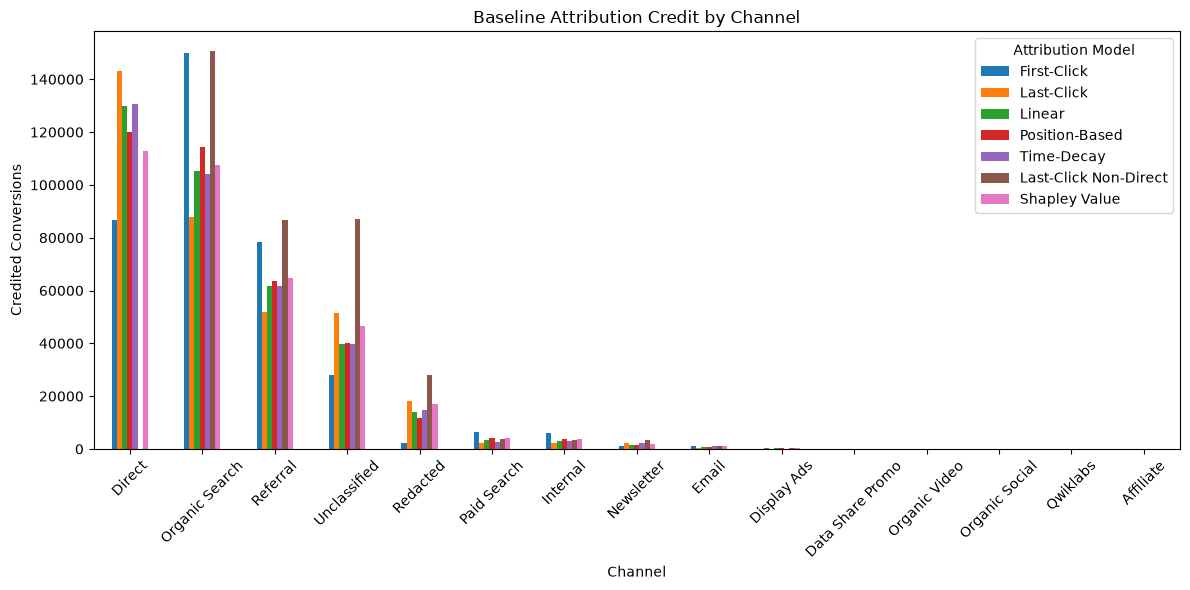

In [48]:
# Plot the attribution models
df = attribution_models.copy()
df['medians'] = df.median(axis=1)
df = df.sort_values('medians', ascending=False).drop(columns='medians')
#df = df[df.median(axis=1).sort_values(ascending=False).index.values]
df.plot(kind='bar', figsize=(12,6))

plt.title("Baseline Attribution Credit by Channel")
plt.ylabel("Credited Conversions")
plt.xlabel("Channel")
plt.xticks(rotation=45)
plt.legend(title="Attribution Model")
plt.tight_layout()
plt.show()

#### Markov Attribution Model

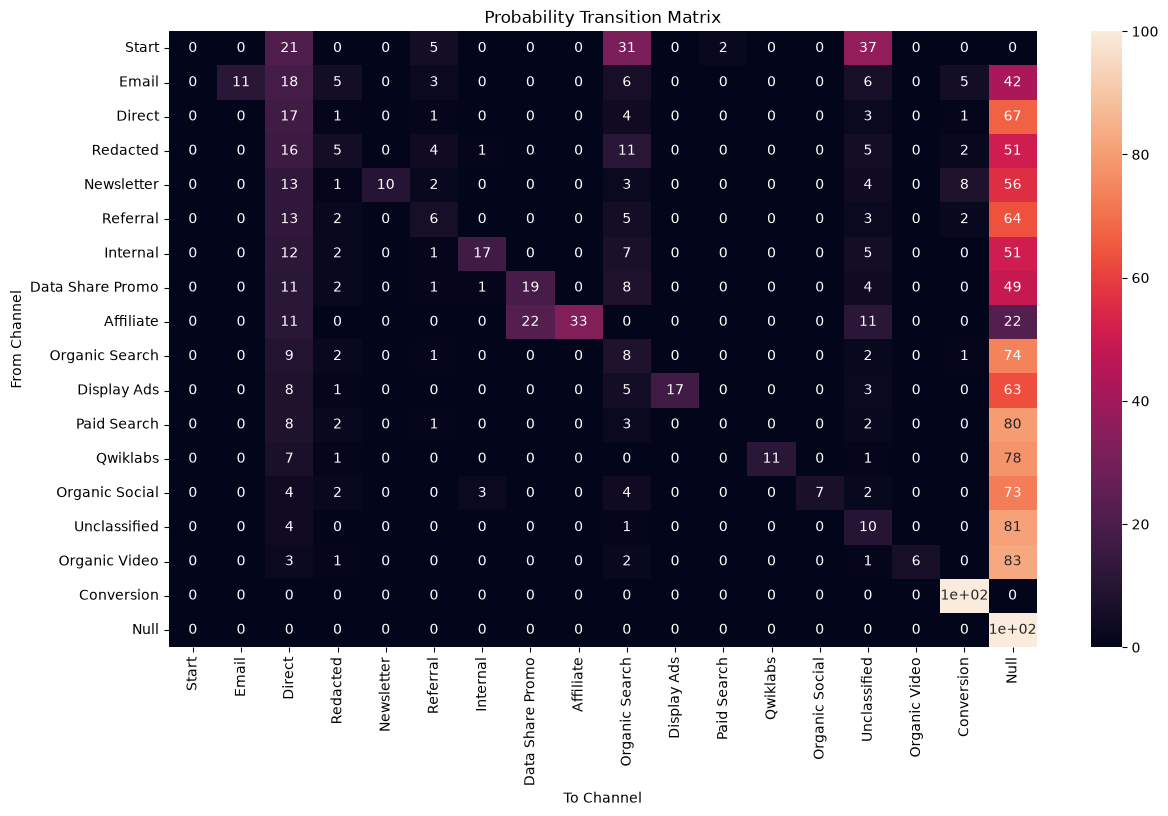

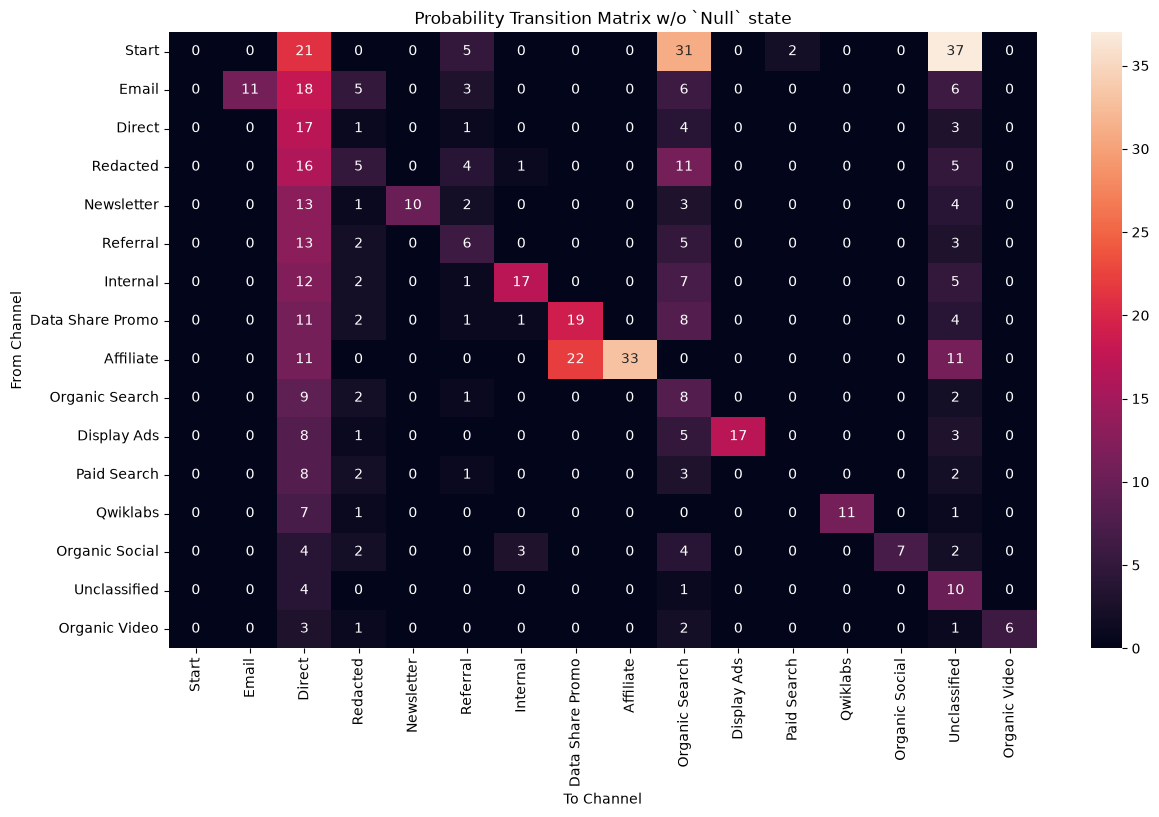

In [49]:
from collections import defaultdict

def build_transition_matrix(df_original):
    df = df_original.copy()

    # Calculate the transition pairs
    transitions = defaultdict(int)
    for _, row in df.iterrows():
        if row['has_conversion']:
            steps = row['conversion_path'] + ['Conversion']
        else:
            steps = row['conversion_path'] + ['Null']
        steps = ['Start'] + steps

        for i in range(len(steps) - 1):
            #count = row['counts']
            transitions[(steps[i], steps[i+1])] += 1
    return transitions


def plot_transition_matrix(df):
    transition_matrix = df.copy()
    transition_matrix = (transition_matrix * 100).astype(int)

    # Plot transition matrix as a heatmap
    fig, ax = plt.subplots(figsize=(14,8))
    sns.heatmap(transition_matrix, annot=True)
    ax.set_xlabel('To Channel')
    ax.set_ylabel('From Channel')
    ax.set_title('Probability Transition Matrix')

    # Plot transition matrix w/o absorption states
    transition_matrix = transition_matrix.drop(columns=['Null', 'Conversion'], index=['Null', 'Conversion'])
    fig, ax = plt.subplots(figsize=(14,8))
    sns.heatmap(transition_matrix, annot=True)
    ax.set_xlabel('To Channel')
    ax.set_ylabel('From Channel')
    ax.set_title('Probability Transition Matrix w/o `Null` state')

# Build the transition probabilities
transitions = build_transition_matrix(journeys)

# Add starting column
transitions[('Conversion', 'Start')] = 0

# Add absorption states
transitions[('Conversion', 'Conversion')] = 1
transitions[('Null', 'Null')] = 1

# Create the transition probability matrix
transition_matrix = pd.Series(transitions).unstack(fill_value=0).fillna(0)
transition_matrix = transition_matrix.div(transition_matrix.sum(axis=1),axis=0) # The number of transitions to state i divided by the total number of transitions.
transition_matrix = transition_matrix.sort_values('Direct', ascending=False) 
transition_matrix = transition_matrix[transition_matrix.index.values] # Reorder for symmetric axes.
plot_transition_matrix(transition_matrix)


In [50]:

def removal_effect(transitions_df, channel):
    G = nx.DiGraph()
    for _, row in transitions_df.iterrows():
        if row['From'] == channel or row['To'] == channel:
            continue
        G.add_edge(row['From'], row['To'], weight=row['Prob'])
    
    # Monte Carlo simulation of conversion probability
    n_sim = 30000
    conv = 0
    for _ in range(n_sim):
        state = "Start"
        while state not in ['Conversion', 'Null']:
            if state not in G:
                state = 'Null'
                break
            next_states = list(G[state])
            probs = [G[state][n]['weight'] for n in next_states]
            state = np.random.choice(next_states, p=np.array(probs)/np.sum(probs))
        if state == 'Conversion':
            conv += 1
    return conv / n_sim

markov_credits = []
n_sims = 30
for _ in range(n_sims):

    # Get transition probabilities as a dataframe
    df_trans = pd.DataFrame([(a,b,c) for (a,b),c in transitions.items()],
                                columns=['From','To','Count'])

    df_trans["Prob"] = df_trans.groupby("From")["Count"].transform(lambda x: x / x.sum())

    # Get conversion probability with all channel intact
    base_conv = removal_effect(df_trans, channel=None)

    # Removal effect per channel
    markov_credit = {}
    for ch in sessions['channel'].unique():
        conv_rate = removal_effect(df_trans, channel=ch)
        markov_credit[ch] = base_conv - conv_rate

    markov_credits.append(markov_credit)


In [51]:
markov_credit = pd.DataFrame(markov_credits).melt()
df = markov_credit.groupby('variable').agg(
    mean = ('value', 'mean'),
    sem = ('value', 'sem')
).reset_index().rename(columns={'variable': 'Channel', 'mean': 'Removal Effect'})

df['Color'] = np.where(df['Removal Effect'].lt(0), '#d95b5b', '#169122')

df = df.sort_values('Removal Effect')
fig = go.Figure()
fig.add_trace(
    go.Bar(name='Removal Effect',
        y=df['Channel'],
        x=df['Removal Effect'],
        marker_color=df['Color'],
        #text=[f"{i:.4f}" for i in df['Removal Effect']],
        error_x=dict(
                    type='data',
                    array=df['sem'],
                    visible=True
        ),
        #textposition='auto',
        orientation='h',
    )
)
fig.show()

- The `Direct`, `Referral`, `Redacted` are the strongest assist channels with `Direct` and `Referral` being the most important.
<br>
<br>
- The `Unclassified` channel has the most negative value, which suggests that this channel is helping in driving conversions. However, these channels are not known, so it would be beneficial to find out what campaigns are involved in this channel to investigate further.
<br>
<br>
- Since this is a monte carlo simulation, the results are probabilistic and for a quick run of the code, I settled on 30 resamples of 30,000 simulations. The errorbars are still quite large and sometimes pass through the y-axis. However, it can confidently be stated that the `Unclassified` channel is not driving incremental conversion, while the `Direct` and `Referral` channels are. `Redacted`, like `Unclassified` are unknown channels but purposively obfuscated for privacy reasons.

In [52]:
def calculate_conversion_probability(df, transient_channels):
    P_matrix = df.copy()

    # Extract Q (transient to transient) and R (transient to absorbing)
    Q = P_matrix.loc[transient_channels, transient_channels].to_numpy()
    R = P_matrix.loc[transient_channels, ['Conversion', 'Null']].to_numpy()

    # The expected number of visits to a transient state
    I = np.identity(len(transient_channels))
    N = np.linalg.inv(I - Q)
    
    # B = NR matrix, contains absorbing probabilities (Conversion is index 0, Null is index 1)
    B = np.matmul(N,R)
    
    # Return Starting Conversion Probability
    return B[0, 0] # Start is the first column

# Get the transient channel names
transient_channels = [col for col in transition_matrix.columns if col not in ['Conversion', 'Null']]

# Calculate the conversion probability when all channels are intact.
base_conv = calculate_conversion_probability(transition_matrix, transient_channels)

# Calculate the conversion probability when removing one channel.
conversion_probs = defaultdict(float)
for channel in sessions['channel'].unique():
    temp = transition_matrix.copy()
    temp[channel] = temp[channel] * 0
    conversion_probs[channel] = calculate_conversion_probability(temp, transient_channels)

 # Calculate the removal effect and normalize it.
removal_effect = 1.0 - (pd.Series(conversion_probs) / base_conv)
removal_effect = (removal_effect / removal_effect.sum()) 

# Markov Attribution Model
markov_chain_attr = removal_effect * journeys['conversion_value_usd'].sum()
attribution_models = pd.concat([attribution_models, markov_chain_attr.rename('Markov Chain')], axis=1)

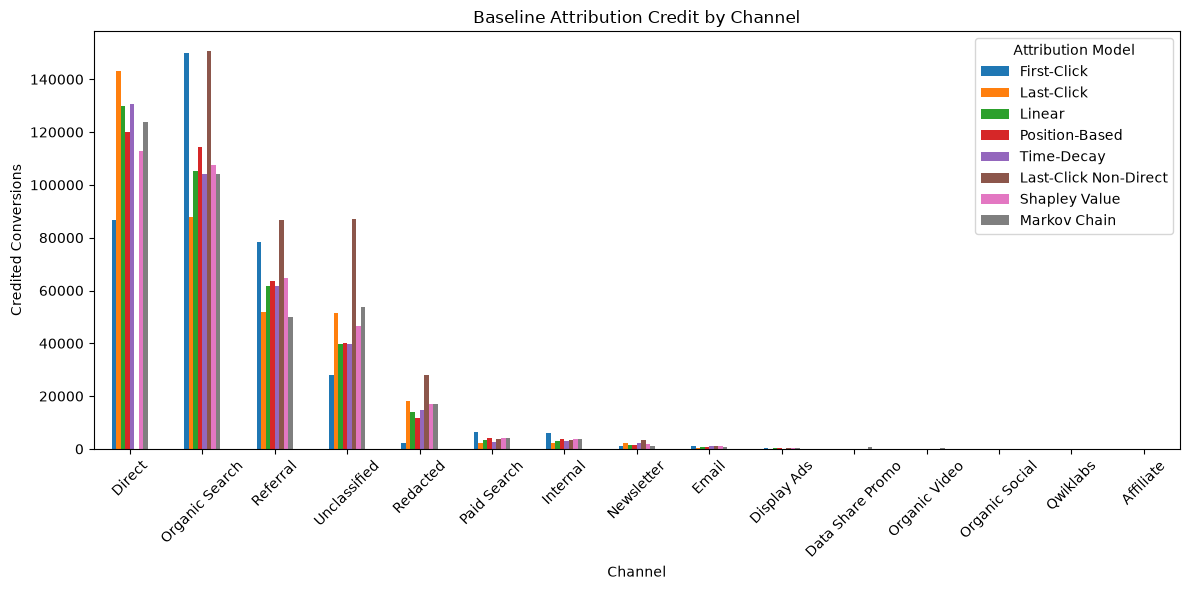

In [53]:
# Plot the attribution models
df = attribution_models.copy()
df['medians'] = df.median(axis=1)
df = df.sort_values('medians', ascending=False).drop(columns='medians')
#df = df[df.median(axis=1).sort_values(ascending=False).index.values]
df.plot(kind='bar', figsize=(12,6))

plt.title("Baseline Attribution Credit by Channel")
plt.ylabel("Credited Conversions")
plt.xlabel("Channel")
plt.xticks(rotation=45)
plt.legend(title="Attribution Model")
plt.tight_layout()
plt.show()

In [54]:
attribution_models.div(attribution_models.sum(axis=1),axis=0) * 100

,First-Click,Last-Click,Linear,Position-Based,Time-Decay,Last-Click Non-Direct,Shapley Value,Markov Chain
Data Share Promo,1.838107,11.428232,3.040869,5.306536,8.273081,11.428232,6.326818,52.358125
Direct,10.236619,16.911192,15.347502,14.153398,15.410717,0.000000,13.327608,14.612964
Display Ads,16.768542,2.255418,12.994149,10.484752,7.272742,20.985193,18.774720,10.464484
Email,13.683248,6.890845,12.727109,10.928879,13.616309,16.481775,15.306347,10.365488
Internal,20.362024,7.613173,10.902926,13.139343,9.799902,12.112972,12.983802,13.085859
Newsletter,6.552019,15.054282,9.986118,10.802082,14.252210,22.481239,12.837437,8.034613
Organic Search,16.227628,9.517508,11.397598,12.378302,11.269982,16.296439,11.633120,11.279423
Organic Social,6.191773,6.191773,6.191773,6.191773,6.191773,6.191773,6.191773,56.657588
Organic Video,10.986127,4.732485,9.887514,9.076231,9.601875,9.972023,10.901618,34.842127
Paid Search,21.088176,6.867405,11.070206,12.941094,8.951157,11.854906,13.619714,13.607342


### Creating Relational DataBase

In [55]:
raw_dimensions = raw.dimensions.to_pandas()
raw_dimensions.head()

,user_pseudo_id,event_timestamp_micros,event_date,continent,country,region,city,first_touch,device_category,device_language,device_brand_name,device_model_name,device_os,device_os_version
0,3952083.8521143850,2020-12-25 20:49:25.159202+00:00,2020-12-25,Americas,United States,North Carolina,Raleigh,2020-12-25 20:49:25.159202+00:00,mobile,en-us,Google,Pixel 4 XL,Web,<Other>
1,6891577.6842406890,2020-12-25 11:26:04.905936+00:00,2020-12-25,Europe,Russia,(not set),(not set),2020-12-25 11:26:04.905936+00:00,mobile,NaN,Google,Pixel 3,Web,<Other>
2,8511848.0344447876,2020-12-25 13:48:31.543619+00:00,2020-12-25,Asia,Turkey,Istanbul,Istanbul,2020-12-25 13:48:31.543619+00:00,mobile,NaN,Google,Pixel 4 XL,Web,<Other>
3,8885678.2536198286,2020-12-25 04:11:29.734020+00:00,2020-12-25,Americas,Canada,Quebec,(not set),2020-12-25 03:37:16.831635+00:00,mobile,zh,Google,Pixel 3,Web,<Other>
4,38924860.7374244980,2020-12-25 13:09:44.783216+00:00,2020-12-25,Asia,Turkey,Ankara,Ankara,2020-12-25 13:09:44.783216+00:00,mobile,NaN,Google,Pixel 4 XL,Web,<Other>


#### Traffic Source Dimension Table

In [57]:
def clean_unknown(df_original,cols):
    df = df_original.copy()
    for col in cols:
        df[col] = (df[col].str.lower().replace('', 'unspecified').replace('(not set)', 'unspecified').replace('<other>', 'unspecified')
                    .replace('(direct)', 'direct').replace('(none)', 'unspecified').replace('(organic)', 'organic')
                    .replace('(data deleted)', 'redacted').replace('(referral)', 'referral'))
    return df

def create_dim(df_original, cols, id_name):
    df = df_original.copy()
    df = df[cols].drop_duplicates().reset_index(drop=True)
    df = clean_unknown(df,cols)
    df = df.reset_index().rename(columns={'index': id_name})
    return df

traffic_cols = ['source_utm', 'medium_utm', 'campaign_utm', 'channel']

# traffic_source dimension table
traffic_source_dim = create_dim(sessions, traffic_cols, 'traffic_source_id')
display(traffic_source_dim)

session_traffic = sessions.merge(traffic_source_dim, on=traffic_cols, how='left')[['session_id', 'traffic_source_id']].drop_duplicates()
df = sessions.sort_values(['user_pseudo_id', 'session_start']).groupby('user_pseudo_id')[traffic_cols].first().reset_index()
user_traffic = df.merge(traffic_source_dim, on=traffic_cols, how='left')[['user_pseudo_id', 'traffic_source_id']].drop_duplicates()

display(user_traffic.head())

,traffic_source_id,source_utm,medium_utm,campaign_utm,channel
0,0,unspecified,unspecified,unspecified,unclassified
1,1,direct,unspecified,direct,direct
2,2,unspecified,unspecified,unspecified,unclassified
3,3,google,organic,organic,organic search
4,4,unspecified,organic,organic,organic search
...,...,...,...,...,...
92,92,m.sm.cn,referral,referral,referral
93,93,google,unspecified,unspecified,organic search
94,94,m.sp.sm.cn,referral,referral,referral
95,95,partners,affiliate,referral,affiliate


,user_pseudo_id,traffic_source_id
0,10001363.4360935308,NaN
1,1000223163.8035209215,NaN
2,1000299.7413851356,NaN
3,1000300.3223254235,NaN
4,10003031.4607645453,NaN


#### Date Dimension Table

In [58]:
df = pl.from_pandas(transformed_events['event_date'].copy())
df = df.unique()
df = pl.DataFrame(df)
df = df.with_columns(
    pl.col('event_date').dt.strftime('%Y%m%d').cast(pl.Int32).alias('date_id'),
    pl.col('event_date').dt.year().alias('year'),
    pl.col('event_date').dt.quarter().alias('quarter'),
    pl.col('event_date').dt.month().alias('month'),
    pl.col('event_date').dt.strftime('%B').alias('month_name'),
    pl.col('event_date').dt.day().alias('day'),
    pl.col('event_date').dt.weekday().alias('day_of_week'),
    pl.col('event_date').dt.strftime('%A').alias('day_name'),
    pl.col('event_date').dt.weekday().is_in([6,7]).alias('is_weekend')
)
df = df.to_pandas()
df = df.rename(columns={'event_date': 'datetime'})
cols = df.columns.to_list()
cols.remove('date_id')
df = df[['date_id'] + cols]
display(df.head(9))

,date_id,datetime,year,quarter,month,month_name,day,day_of_week,day_name,is_weekend
0,20201101,2020-11-01,2020,4,11,November,1,7,Sunday,True
1,20201102,2020-11-02,2020,4,11,November,2,1,Monday,False
2,20201103,2020-11-03,2020,4,11,November,3,2,Tuesday,False
3,20201104,2020-11-04,2020,4,11,November,4,3,Wednesday,False
4,20201105,2020-11-05,2020,4,11,November,5,4,Thursday,False
5,20201106,2020-11-06,2020,4,11,November,6,5,Friday,False
6,20201107,2020-11-07,2020,4,11,November,7,6,Saturday,True
7,20201108,2020-11-08,2020,4,11,November,8,7,Sunday,True
8,20201109,2020-11-09,2020,4,11,November,9,1,Monday,False


#### Device Dimension Table (many-to-many)

Transform data to be one-to-many -> (take the first event device_id)

In [62]:
# Create the device dimension table
device_cols = ['device_category', 'device_brand_name', 'device_model_name', 'device_os', 'device_os_version']
df = raw_dimensions.sort_values('event_timestamp_micros').groupby('user_pseudo_id')[device_cols].first().reset_index()
device_dim = create_dim(df, device_cols, 'device_id')
display(device_dim.head())

user_device = clean_unknown(df,device_cols).merge(device_dim, on=device_cols, how='left')[['user_pseudo_id', 'device_id']]
display(user_device.head())

,device_id,device_category,device_brand_name,device_model_name,device_os,device_os_version
0,0,desktop,apple,safari,web,unspecified
1,1,mobile,xiaomi,unspecified,web,unspecified
2,2,desktop,google,chrome,web,10
3,3,desktop,google,chrome,windows,windows 10
4,4,mobile,apple,iphone,web,unspecified


,user_pseudo_id,device_id
0,10001363.4360935308,0
1,1000223163.8035209215,1
2,1000299.7413851356,2
3,1000300.3223254235,2
4,10003031.4607645453,3


#### Items Dimension Table

In [65]:
item_cols = ['item_name', 'item_brand', 'item_variant', 'item_category']
df = clean_unknown(clean.items.to_pandas(), item_cols)
df_pl = pl.from_pandas(df)
item_dim = df_pl.group_by('item_name').agg(
    pl.col('item_brand').first().alias('brand'),
    pl.col('item_variant').first().alias('variant'),
    pl.col('item_category').first().alias('category'),
    pl.col('price').max().alias('price'),
)
item_dim = item_dim.to_pandas()
item_dim['price_category'] = pd.qcut(item_dim['price'], q=5, labels=['Cheap', 'Low', 'Medium', 'High', 'Expensive'])
item_dim['sold'] = np.where(item_dim['price'].notna(), 1, 0)
item_dim = item_dim.replace('(not set)', pd.NA)
display(item_dim.head())

,item_name,brand,variant,category,price,price_category,sold
0,google clear framed gray shades,unspecified,unspecified,sale,4.0,Cheap,1
1,youtube leather strap hat black,unspecified,unspecified,home/shop by brand/youtube/,12.0,Low,1
2,google striped penny pouch,google,unspecified,bags,3.0,Cheap,1
3,google 5k run 2020 unisex tee,google,md,unspecified,NaN,NaN,0
4,google lapel pin,unspecified,unspecified,lifestyle,8.0,Low,1


#### Items Funnel Facts Table

In [67]:
item_funnel = clean.items
item_funnel = item_funnel.with_columns(
    pl.col('event_date').dt.strftime('%Y%m%d').cast(pl.Int32).alias('date_id')
)

item_funnel = item_funnel.group_by(['user_pseudo_id','session_id','date_id','item_name']).agg(
    pl.col('event_name').is_in(['select_item', 'view_item']).any().cast(pl.Int8).alias('is_viewed'),
    pl.col('event_name').is_in(['add_to_cart']).any().cast(pl.Int8).alias('is_added_to_cart'),
    pl.col('event_name').is_in(['begin_checkout']).any().cast(pl.Int8).alias('is_checked_out'),
    pl.col('event_name').is_in(['purchase']).any().cast(pl.Int8).alias('is_purchased'),
    pl.col('item_revenue').sum().alias('revenue'),
    pl.col('quantity').filter(pl.col('event_name').eq('purchase')).sum().alias('quantity')
).filter(pl.col('item_name').ne('(not set)'))#.to_pandas()

# Backfilling funnel for strict linear progression:
item_funnel = item_funnel.with_columns(
    pl.when(pl.col('is_purchased').eq(1) | pl.col('is_checked_out').eq(1) | pl.col('is_added_to_cart').eq(1)).then(1).otherwise(pl.col('is_viewed')).alias('is_viewed')
)
item_funnel = item_funnel.with_columns(
    pl.when(pl.col('is_purchased').eq(1) | pl.col('is_checked_out').eq(1)).then(1).otherwise(pl.col('is_added_to_cart')).alias('is_added_to_cart')
)
item_funnel = item_funnel.with_columns(
    pl.when(pl.col('is_purchased').eq(1)).then(1).otherwise(pl.col('is_checked_out')).alias('is_checked_out')
)
item_funnel = item_funnel.to_pandas().reset_index().rename(columns={'index': 'item_funnel_id'})

display(item_funnel[item_funnel['quantity'].gt(1)].sort_values(['user_pseudo_id', 'date_id']).head())


,item_funnel_id,user_pseudo_id,session_id,date_id,item_name,is_viewed,is_added_to_cart,is_checked_out,is_purchased,revenue,quantity
805515,805515,1014825.0200289249,1014825.0200289249-2716419230,20201103,Google Land & Sea French Terry Sweatshirt,1,1,1,1,88.0,2
1071856,1071856,1019527.5799124267,1019527.5799124267-9903438389,20201205,Google Emoji Sticker Pack,1,1,1,1,16.0,4
964804,964804,1021887.1151788384,1021887.1151788384-3688562872,20201226,Google Camp Mug Gray,1,1,1,1,21.0,2
641478,641478,10269098.5703813861,10269098.5703813861-5196652640,20210107,Google Jotter Task Pad,1,1,1,1,66.0,22
857289,857289,1026932.0858862293,1026932.0858862293-8144402352,20201201,Google Sherpa Zip Hoodie Navy,1,1,1,1,110.0,2


- As the funnel currently is, it is not linear. To make this funnel strictly linear, for any stage skipped will be marked as completed.

#### Geolocation Dimension Table (one-to-many)

In [68]:
geo_cols = ['continent', 'country', 'region', 'city']
geo_dim = create_dim(raw_dimensions, geo_cols, 'geo_id')
display(geo_dim.head())
user_geo = clean_unknown(raw_dimensions, geo_cols).merge(geo_dim, on=geo_cols, how='left')[['user_pseudo_id', 'geo_id']].drop_duplicates()

,geo_id,continent,country,region,city
0,0,americas,united states,north carolina,raleigh
1,1,europe,russia,unspecified,unspecified
2,2,asia,turkey,istanbul,istanbul
3,3,americas,canada,quebec,unspecified
4,4,asia,turkey,ankara,ankara
